In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde, wasserstein_distance, ks_2samp, pearsonr, spearmanr
import glob
import os
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import AutoMinorLocator
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
import umap
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import os
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import matplotlib.colors as mcolors


In [2]:
from picosvg.svg import SVG

def save_flat_svg(fig, path, dpi=500):
    fig.savefig(path, dpi=dpi)
    svg = SVG.parse(path).topicosvg()
    with open(path, "w") as f:
        f.write(svg.tostring())

In [3]:
plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
})

# Figure Panel #2

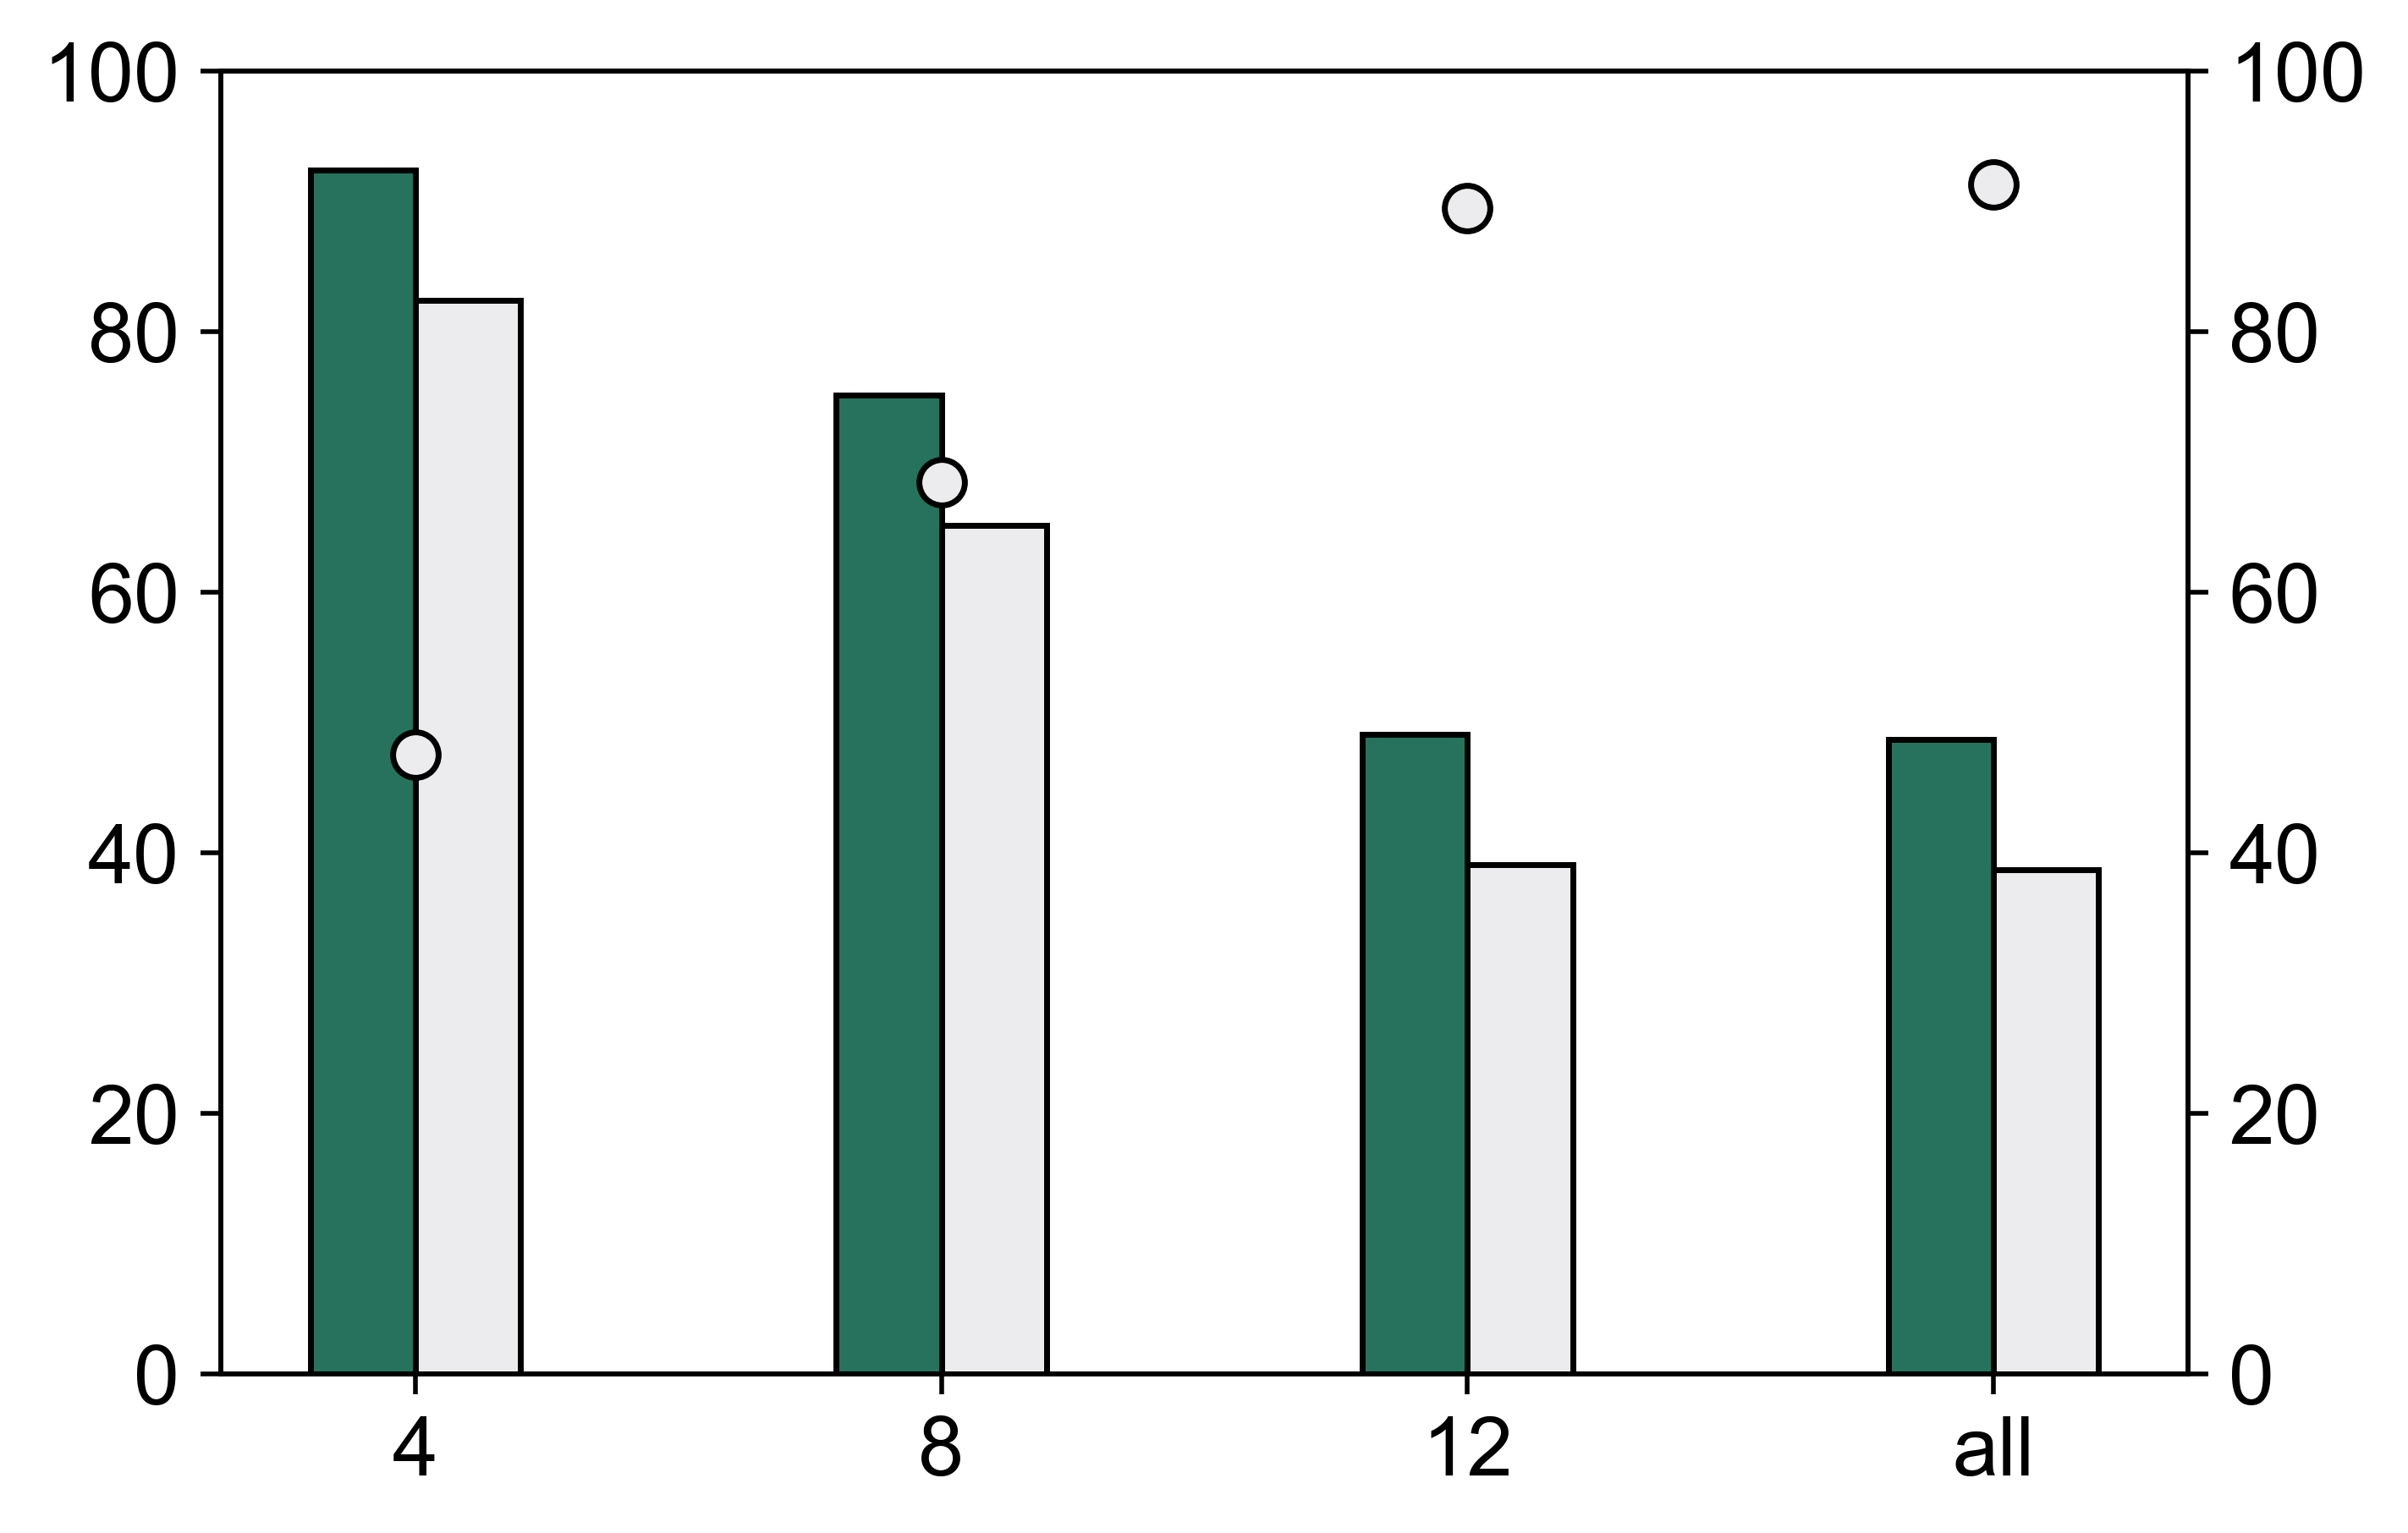

In [4]:
plt.rcParams['font.family'] = 'Arial'

categories = ["4", "8", "12", "all"]

# Dummy values for ID/OOD; "all" ID is the real value from Table 3
id_values = np.array([92.44, 75.15, 49.13, 48.73])   # TODO: replace 4/8/12 with real numbers
ood_values = id_values - 10   # TODO: replace with real numbers

# Dummy uniqueness values (one point per category)
uniqueness_values = np.array([47.57, 68.47, 89.50, 91.32])   # TODO: replace with real numbers

x = np.arange(len(categories))
width = 0.2

fig, ax1 = plt.subplots(figsize=(6, 4), dpi=500)

bars_id = ax1.bar(x - width/2, id_values, width, label="ID", color="#27725D", edgecolor='black' )
bars_ood = ax1.bar(x + width/2, ood_values, width, label="OOD", color="#ECECEE", edgecolor='black' )

ax1.tick_params(axis='both', labelsize=14)

ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, 100)

ax2 = ax1.twinx()
ax2.tick_params(axis='both', labelsize=14)
points_uniqueness = ax2.scatter(x, uniqueness_values, color="#ECECEE", marker="o", edgecolors='black',
                                 s=60, zorder=3, label="Uniqueness")
ax2.set_ylim(0, 100)

# Combine legends from both axes
handles = [bars_id, bars_ood, points_uniqueness]
labels = [h.get_label() for h in handles]

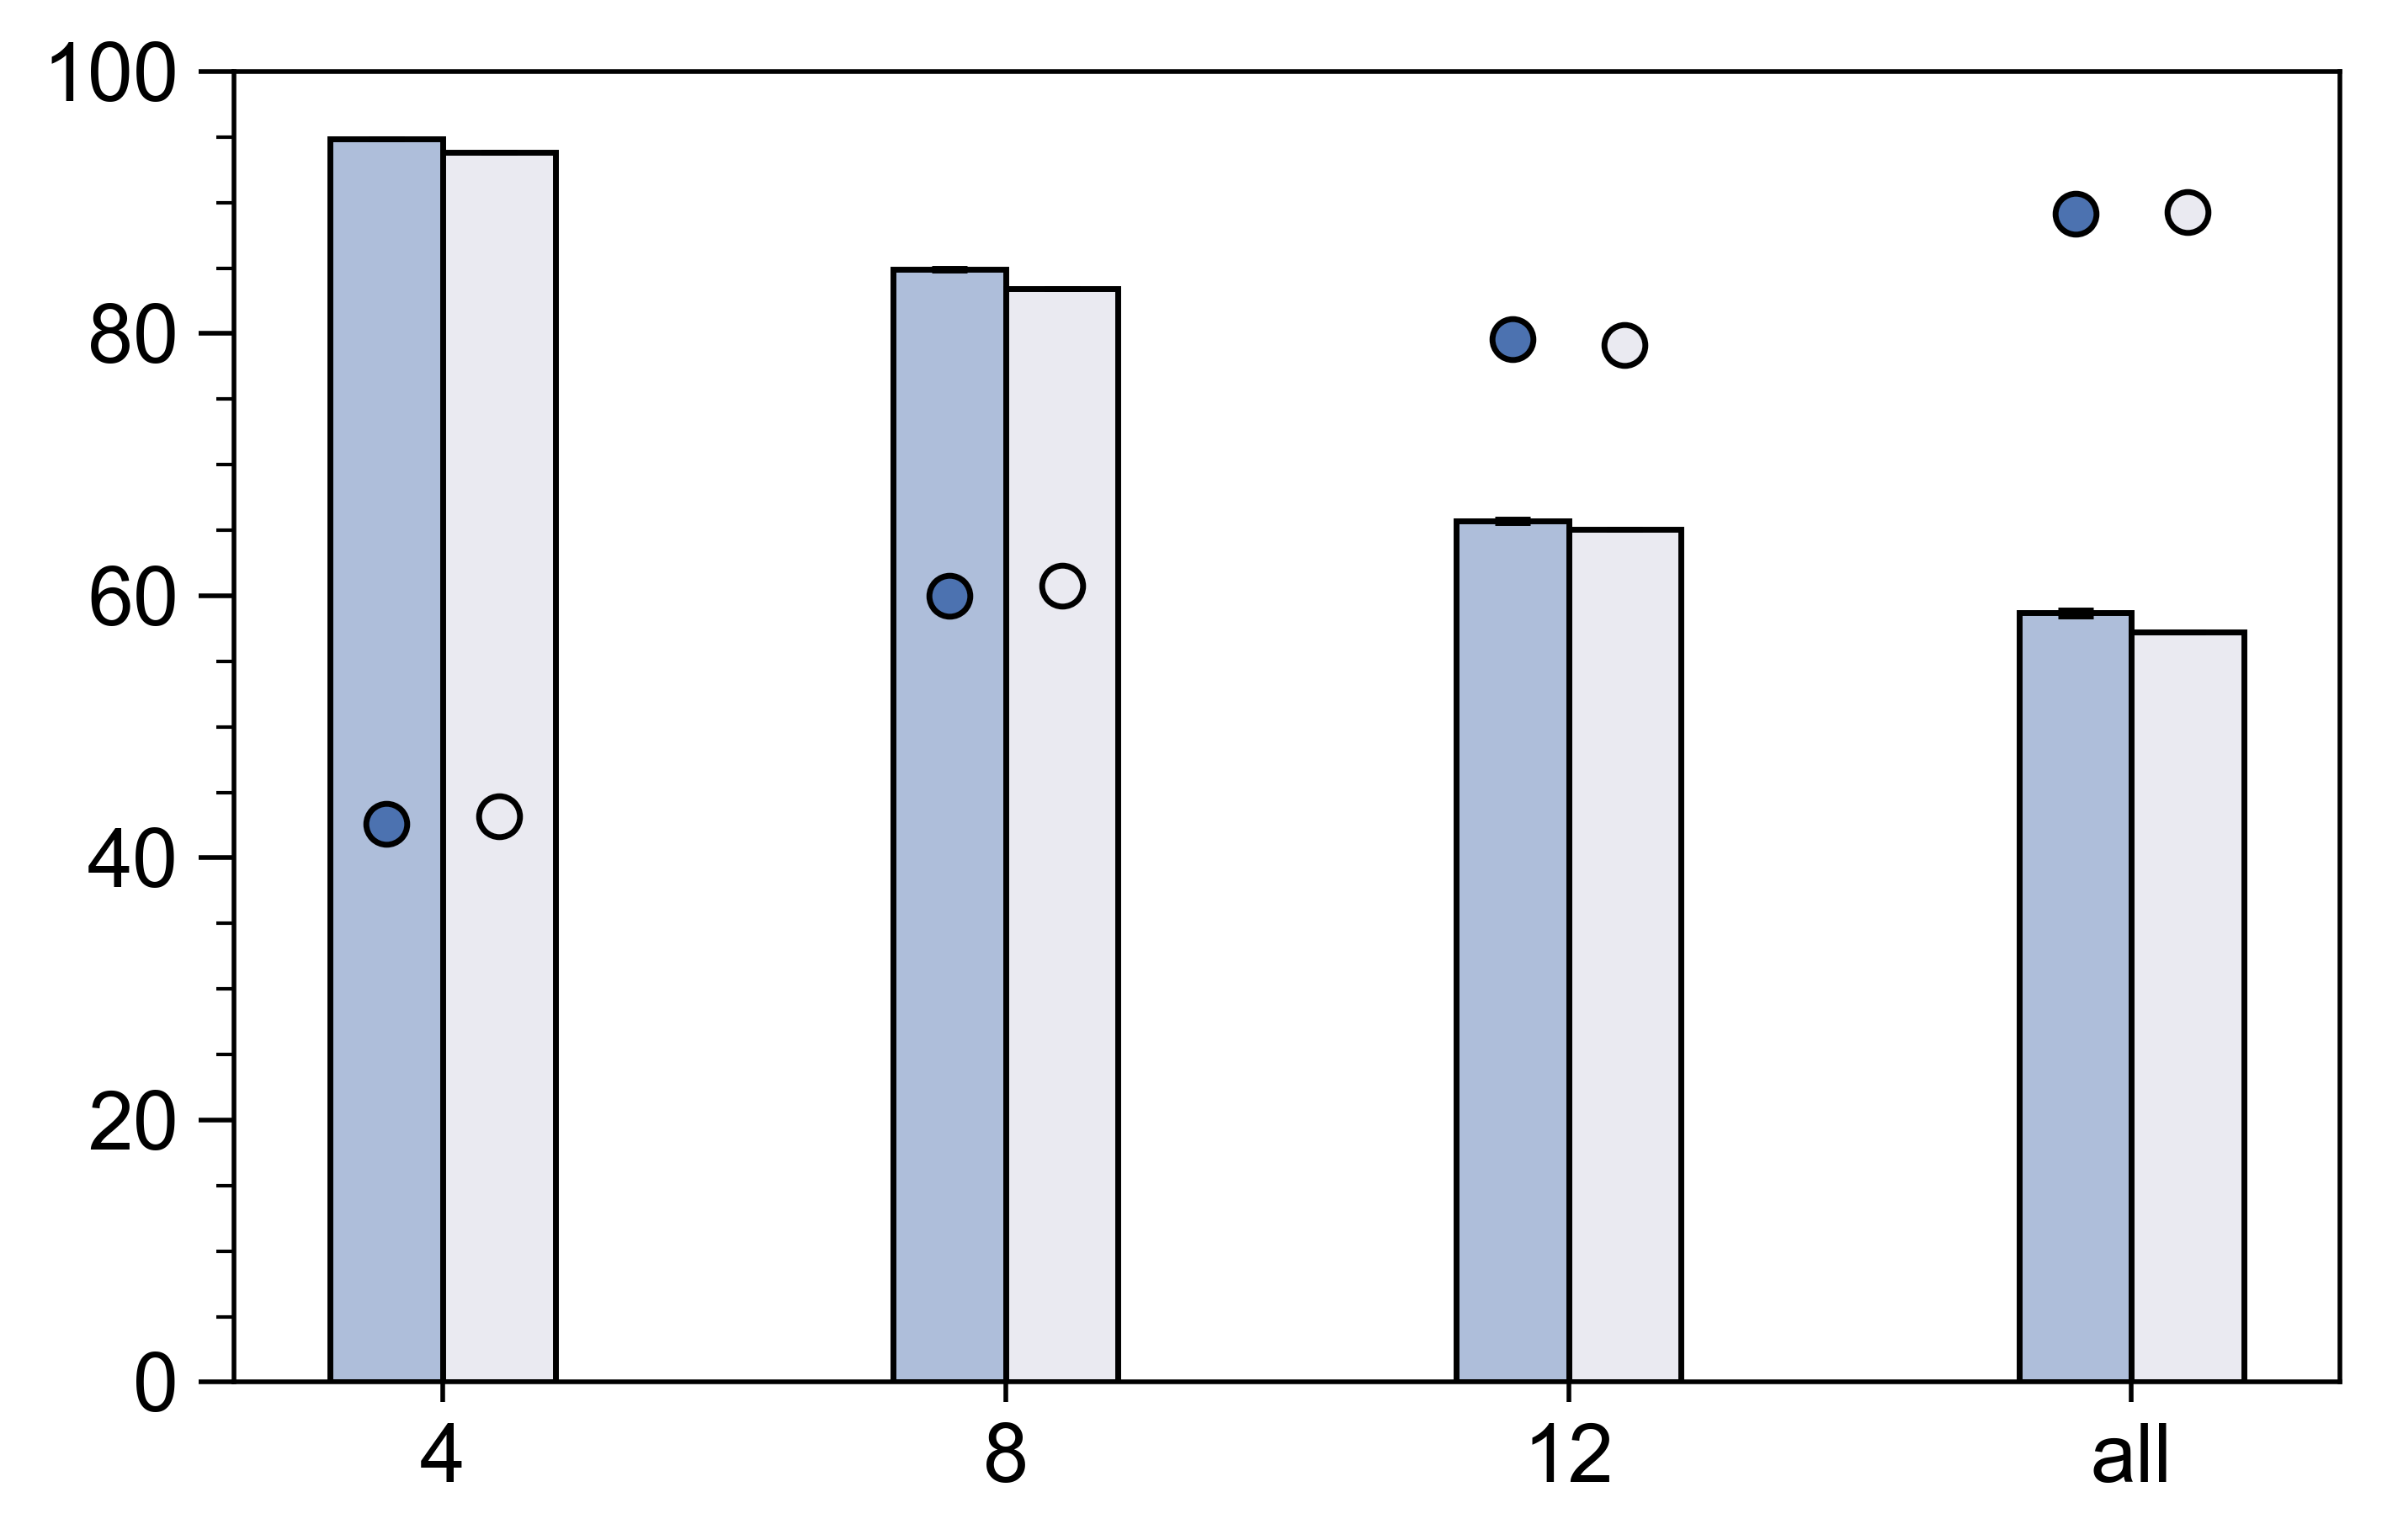

In [5]:
"""
Compare elemental composition diversity between GACE (across seeds) and OC20,
via a back-to-back horizontal bar chart plus Shannon entropy summary stats.

Setup:
  - Sets global matplotlib font sizes (title/axis/tick/legend) for the figure.
  - TOP_N = 20 controls how many elements are shown in the plot.

`load_percent(path)`:
  Reads a CSV, normalizes column names (strip + lowercase), locates the
  "element" and "count" columns, and returns a pandas Series mapping
  element -> percent of total count (values sum to 100).

`shannon_entropy(pct_series)`:
  Computes Shannon entropy in nats from a Series of percentages (converts
  to probabilities, drops zeros, returns -sum(p * log(p))).

Main flow:
  1. Loads elemental composition percentages for three GACE seeds
     (0, 7, 42) and for OC20 from CSV files in "./data/".
  2. Builds the union of all elements seen across the three GACE seeds and
     OC20, and reindexes every series onto that common element set,
     filling missing elements with 0.0.
  3. Stacks the three GACE seed series and computes, per element, the mean
     (`gace`) and std (`gace_err`) across seeds.
  4. Computes and prints Shannon entropy (and "effective diversity" =
     exp(entropy), i.e. the effective number of equally-likely elements)
     for both OC20 and the seed-averaged GACE distribution.
  5. Ranks elements by combined (GACE + OC20) percentage, takes the top
     TOP_N, and reverses the order so the largest ends up at the top of
     the plot.
  6. Plots a horizontal "tornado" / back-to-back bar chart: GACE
     percentages extend right (with seed-std error bars), OC20 percentages
     extend left (plotted as negative values), sharing a common y-axis of
     element labels. X-tick labels are converted to their absolute value
     so both sides read as positive percentages.
  7. Draws a vertical line at x=0, tightens layout, and saves the figure
     as an SVG via `save_flat_svg`.

Note: this saves to the same path as the previous panel
("fig2/panel/val_uniq_gaussian.svg") — looks like a copy-pasted filename
that wasn't updated, so it will silently overwrite that earlier figure.
"""

categories = ["4", "8", "12", "all"]

# Validity across different seeds
id_values_0 = np.array([94.89, 84.80, 65.50, 58.61])
ood_values_0 = np.array([93.82, 83.41, 65.06, 57.23])

id_values_7 = np.array([94.84, 84.90, 65.76, 58.98])
ood_values_7 = np.array([93.82, 83.41, 65.06, 57.23])

id_values_42 = np.array([94.86, 85.01, 65.87, 58.46])
ood_values_42 = np.array([93.82, 83.41, 65.06, 57.23])

# Uniqueness across different seeds
id_uniqueness_0 = np.array([42.89, 60.66, 79.71, 89.10])
ood_uniqueness_0 = np.array([43.17, 60.74, 79.16, 89.29])

id_uniqueness_7 = np.array([42.43, 60.50, 79.60, 89.19])
ood_uniqueness_7 = np.array([43.17, 60.74, 79.16, 89.29])

id_uniqueness_42 = np.array([42.43, 58.81, 79.39, 89.17])
ood_uniqueness_42 = np.array([43.17, 60.74, 79.16, 89.29])

# Stack across seeds -> shape (3, len(categories))
id_values_all = np.stack([id_values_0, id_values_7, id_values_42])
ood_values_all = np.stack([ood_values_0, ood_values_7, ood_values_42])
id_uniqueness_all = np.stack([id_uniqueness_0, id_uniqueness_7, id_uniqueness_42])
ood_uniqueness_all = np.stack([ood_uniqueness_0, ood_uniqueness_7, ood_uniqueness_42])

# Mean and std (ddof=0; use ddof=1 if you want sample std)
id_values, id_values_err = id_values_all.mean(axis=0), id_values_all.std(axis=0)
ood_values, ood_values_err = ood_values_all.mean(axis=0), ood_values_all.std(axis=0)
id_uniqueness, id_uniqueness_err = id_uniqueness_all.mean(axis=0), id_uniqueness_all.std(axis=0)
ood_uniqueness, ood_uniqueness_err = ood_uniqueness_all.mean(axis=0), ood_uniqueness_all.std(axis=0)

x = np.arange(len(categories))
width = 0.2

fig_b, ax1 = plt.subplots(figsize=(6, 4), dpi=500)

bars_id = ax1.bar(x - width/2, id_values, width, yerr=id_values_err, capsize=3,
                   error_kw=dict(elinewidth=1, capthick=1),
                   label="ID", color="#AEBEDA", edgecolor='black')
bars_ood = ax1.bar(x + width/2, ood_values, width, yerr=ood_values_err, capsize=3,
                    error_kw=dict(elinewidth=1, capthick=1),
                    label="OOD", color="#EAEAF1", edgecolor='black')

ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, 100)
ax1.tick_params(axis='both', labelsize=14)

# Minor ticks on the (only) y-axis
ax1.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax1.tick_params(axis='y', which='minor', length=3)
ax1.tick_params(axis='y', which='major', length=6)

# Uniqueness points aligned to the center of each corresponding bar
points_id_uniq = ax1.errorbar(x - width/2, id_uniqueness, yerr=id_uniqueness_err,
                               fmt='o', color="#4C72B0", markeredgecolor='black',
                               ecolor='black', elinewidth=1, capsize=3,
                               markersize=7, zorder=3, label="ID Uniqueness")
points_ood_uniq = ax1.errorbar(x + width/2, ood_uniqueness, yerr=ood_uniqueness_err,
                                fmt='o', color="#EAEAF1", markeredgecolor='black',
                                ecolor='black', elinewidth=1, capsize=3,
                                markersize=7, zorder=3, label="OOD Uniqueness")

# Combine legends
handles = [bars_id, bars_ood, points_id_uniq, points_ood_uniq]
labels = [h.get_label() for h in handles]

plt.tight_layout()
save_flat_svg(fig=fig_b, path="fig2/panel/val_uniq_gaussian.svg")
plt.show()

OC20 entropy: 3.881 nats  (effective diversity: 48.45 elements)
GACE entropy: 3.857 nats  (effective diversity: 47.32 elements)


/var/folders/sl/r8hdl4bx3j9303t8kxh1v50w0000gn/T/ipykernel_50106/2245048353.py:91: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([f"{abs(t):.0f}" for t in xt])


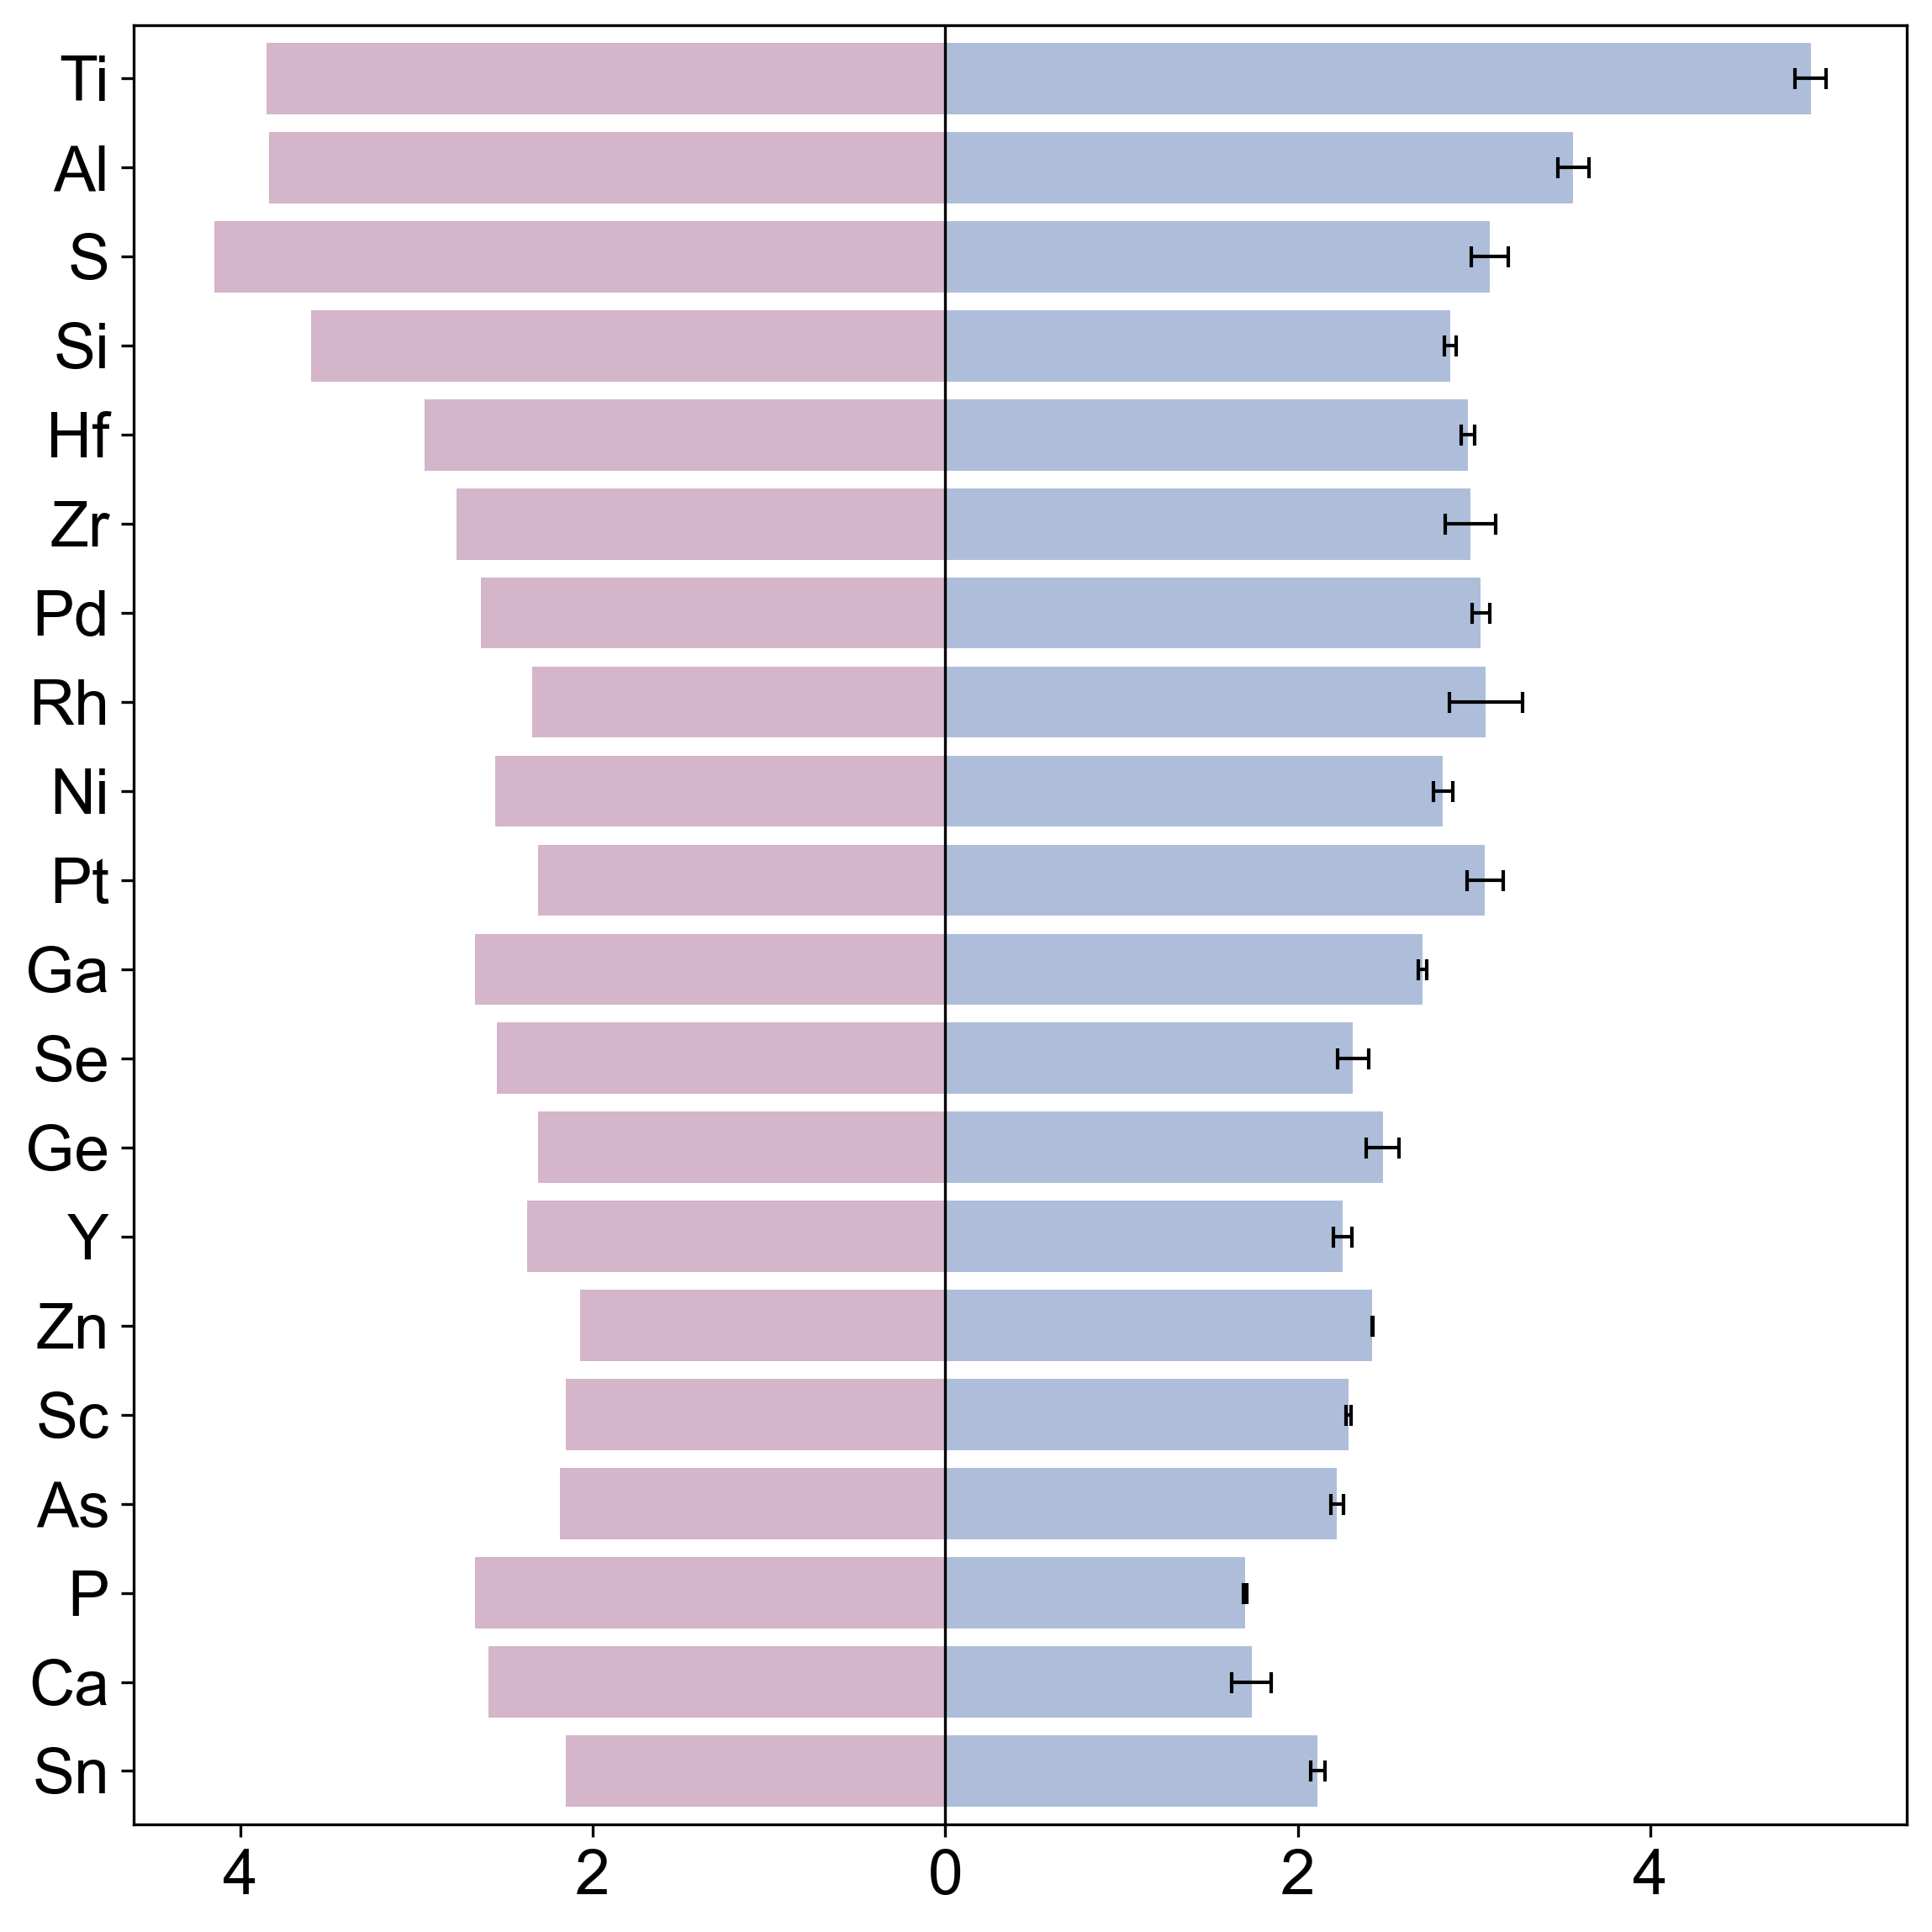

In [6]:
"""
Compare elemental composition diversity between GACE (across seeds) and OC20,
via a back-to-back horizontal bar chart plus Shannon entropy summary stats.

`load_percent(path)`:
  Reads a CSV, normalizes column names (strip + lowercase), locates the
  "element" and "count" columns, and returns a pandas Series mapping
  element -> percent of total count (values sum to 100).

`shannon_entropy(pct_series)`:
  Computes Shannon entropy in nats from a Series of percentages (converts
  to probabilities, drops zeros, returns -sum(p * log(p))).

Main flow:
  1. Loads elemental composition percentages for three GACE seeds
     (0, 7, 42) and for OC20 from CSV files in "./data/".
  2. Builds the union of all elements seen across the three GACE seeds and
     OC20, and reindexes every series onto that common element set,
     filling missing elements with 0.0.
  3. Stacks the three GACE seed series and computes, per element, the mean
     (`gace`) and std (`gace_err`) across seeds.
  4. Computes and prints Shannon entropy (and "effective diversity" =
     exp(entropy), i.e. the effective number of equally-likely elements)
     for both OC20 and the seed-averaged GACE distribution.
  5. Ranks elements by combined (GACE + OC20) percentage, takes the top
     TOP_N, and reverses the order so the largest ends up at the top of
     the plot.
  6. Plots a horizontal "tornado" / back-to-back bar chart: GACE
     percentages extend right (with seed-std error bars), OC20 percentages
     extend left (plotted as negative values), sharing a common y-axis of
     element labels. X-tick labels are converted to their absolute value
     so both sides read as positive percentages.
  7. Draws a vertical line at x=0, tightens layout, and saves the figure
     as an SVG via `save_flat_svg`.
"""

TOP_N = 20

def load_percent(path):
    df = pd.read_csv(path)
    df.columns = [str(c).strip().lower() for c in df.columns]
    elem_col = next(c for c in df.columns if c == "element")
    count_col = next(c for c in df.columns if c == "count")
    s = df.set_index(elem_col)[count_col].astype(float)
    return s / s.sum() * 100.0

def shannon_entropy(pct_series):
    """Shannon entropy (nats) from a pandas Series of percentages."""
    p = pct_series.values / 100.0
    p = p[p > 0]
    return -np.sum(p * np.log(p))

gace0 = load_percent("./data/oc20_and_gace/elemental_data/gace0_elements.csv")
gace7 = load_percent("./data/oc20_and_gace/elemental_data/gace7_elements.csv")
gace42 = load_percent("./data/oc20_and_gace/elemental_data/gace42_elements.csv")
oc20 = load_percent("./data/oc20_and_gace/elemental_data/oc20_elements.csv")

# Union of all elements across seeds + OC20
elements = sorted(set(gace0.index) | set(gace7.index) | set(gace42.index) | set(oc20.index))

gace0 = gace0.reindex(elements, fill_value=0.0)
gace7 = gace7.reindex(elements, fill_value=0.0)
gace42 = gace42.reindex(elements, fill_value=0.0)
oc20 = oc20.reindex(elements, fill_value=0.0)

# Mean and std across the three GACE seeds
gace_all = np.stack([gace0.values, gace7.values, gace42.values])
gace = pd.Series(gace_all.mean(axis=0), index=elements)
gace_err = pd.Series(gace_all.std(axis=0), index=elements)

H_oc20 = shannon_entropy(oc20)
H_gace = shannon_entropy(gace)

print(f"OC20 entropy: {H_oc20:.3f} nats  (effective diversity: {np.exp(H_oc20):.2f} elements)")
print(f"GACE entropy: {H_gace:.3f} nats  (effective diversity: {np.exp(H_gace):.2f} elements)")

combined = gace + oc20
ranked = combined.sort_values(ascending=False).index.tolist()[:TOP_N]
order = ranked[::-1]  # largest on top
y = np.arange(len(order))

fig_c = plt.figure(figsize=(8, 8), dpi=300)
plt.barh(y, gace.reindex(order).values, xerr=gace_err.reindex(order).values,
         color="#AEBEDA", label="GACE",
         error_kw=dict(elinewidth=1, capsize=3, capthick=1))
plt.barh(y, -oc20.reindex(order).values, color="#D4B5CA", label="OC20")

plt.yticks(y, list(order))

xt = plt.xticks()[0]
plt.gca().set_xticklabels([f"{abs(t):.0f}" for t in xt])

plt.axvline(0, color="black", linewidth=0.8)
plt.margins(y=0.01)
plt.tight_layout()

save_flat_svg(fig=fig_c, path="fig2/panel/elemental_dist.svg")

== O ==
Dropped 2 out of 566 structures
Dataset mean and std: -0.07133507177379009 ± 1.6899759556623215
Mean GACE: 0.013201895704928863 ±  1.8840381915942892
Wasserstein distance b/t GACE and dataset: 0.11155410587510213
== CH2O ==
Dropped 2 out of 375 structures
Dataset mean and std: -1.6163247860800356 ± 1.1391554254763652
Mean GACE: -1.5115637724105537 ±  1.2634483712765332
Wasserstein distance b/t GACE and dataset: 0.16484338864763695
== COCH2OH ==
Dropped 14 out of 2514 structures
Dataset mean and std: -2.718092539086193 ± 1.5696474325101133
Mean GACE: -2.540346486735344 ±  1.6694515810471076
Wasserstein distance b/t GACE and dataset: 0.19842771891579036
== C2H(OH)2 ==
Dropped 1 out of 290 structures
Dataset mean and std: -1.8537488873084447 ± 1.5712464984899868
Mean GACE: -1.750956443973066 ±  1.7720881789062877
Wasserstein distance b/t GACE and dataset: 0.1600378713035589
== C2H4OH ==
Dropped 2 out of 340 structures
Dataset mean and std: -3.5422160420897444 ± 1.0083133023941944


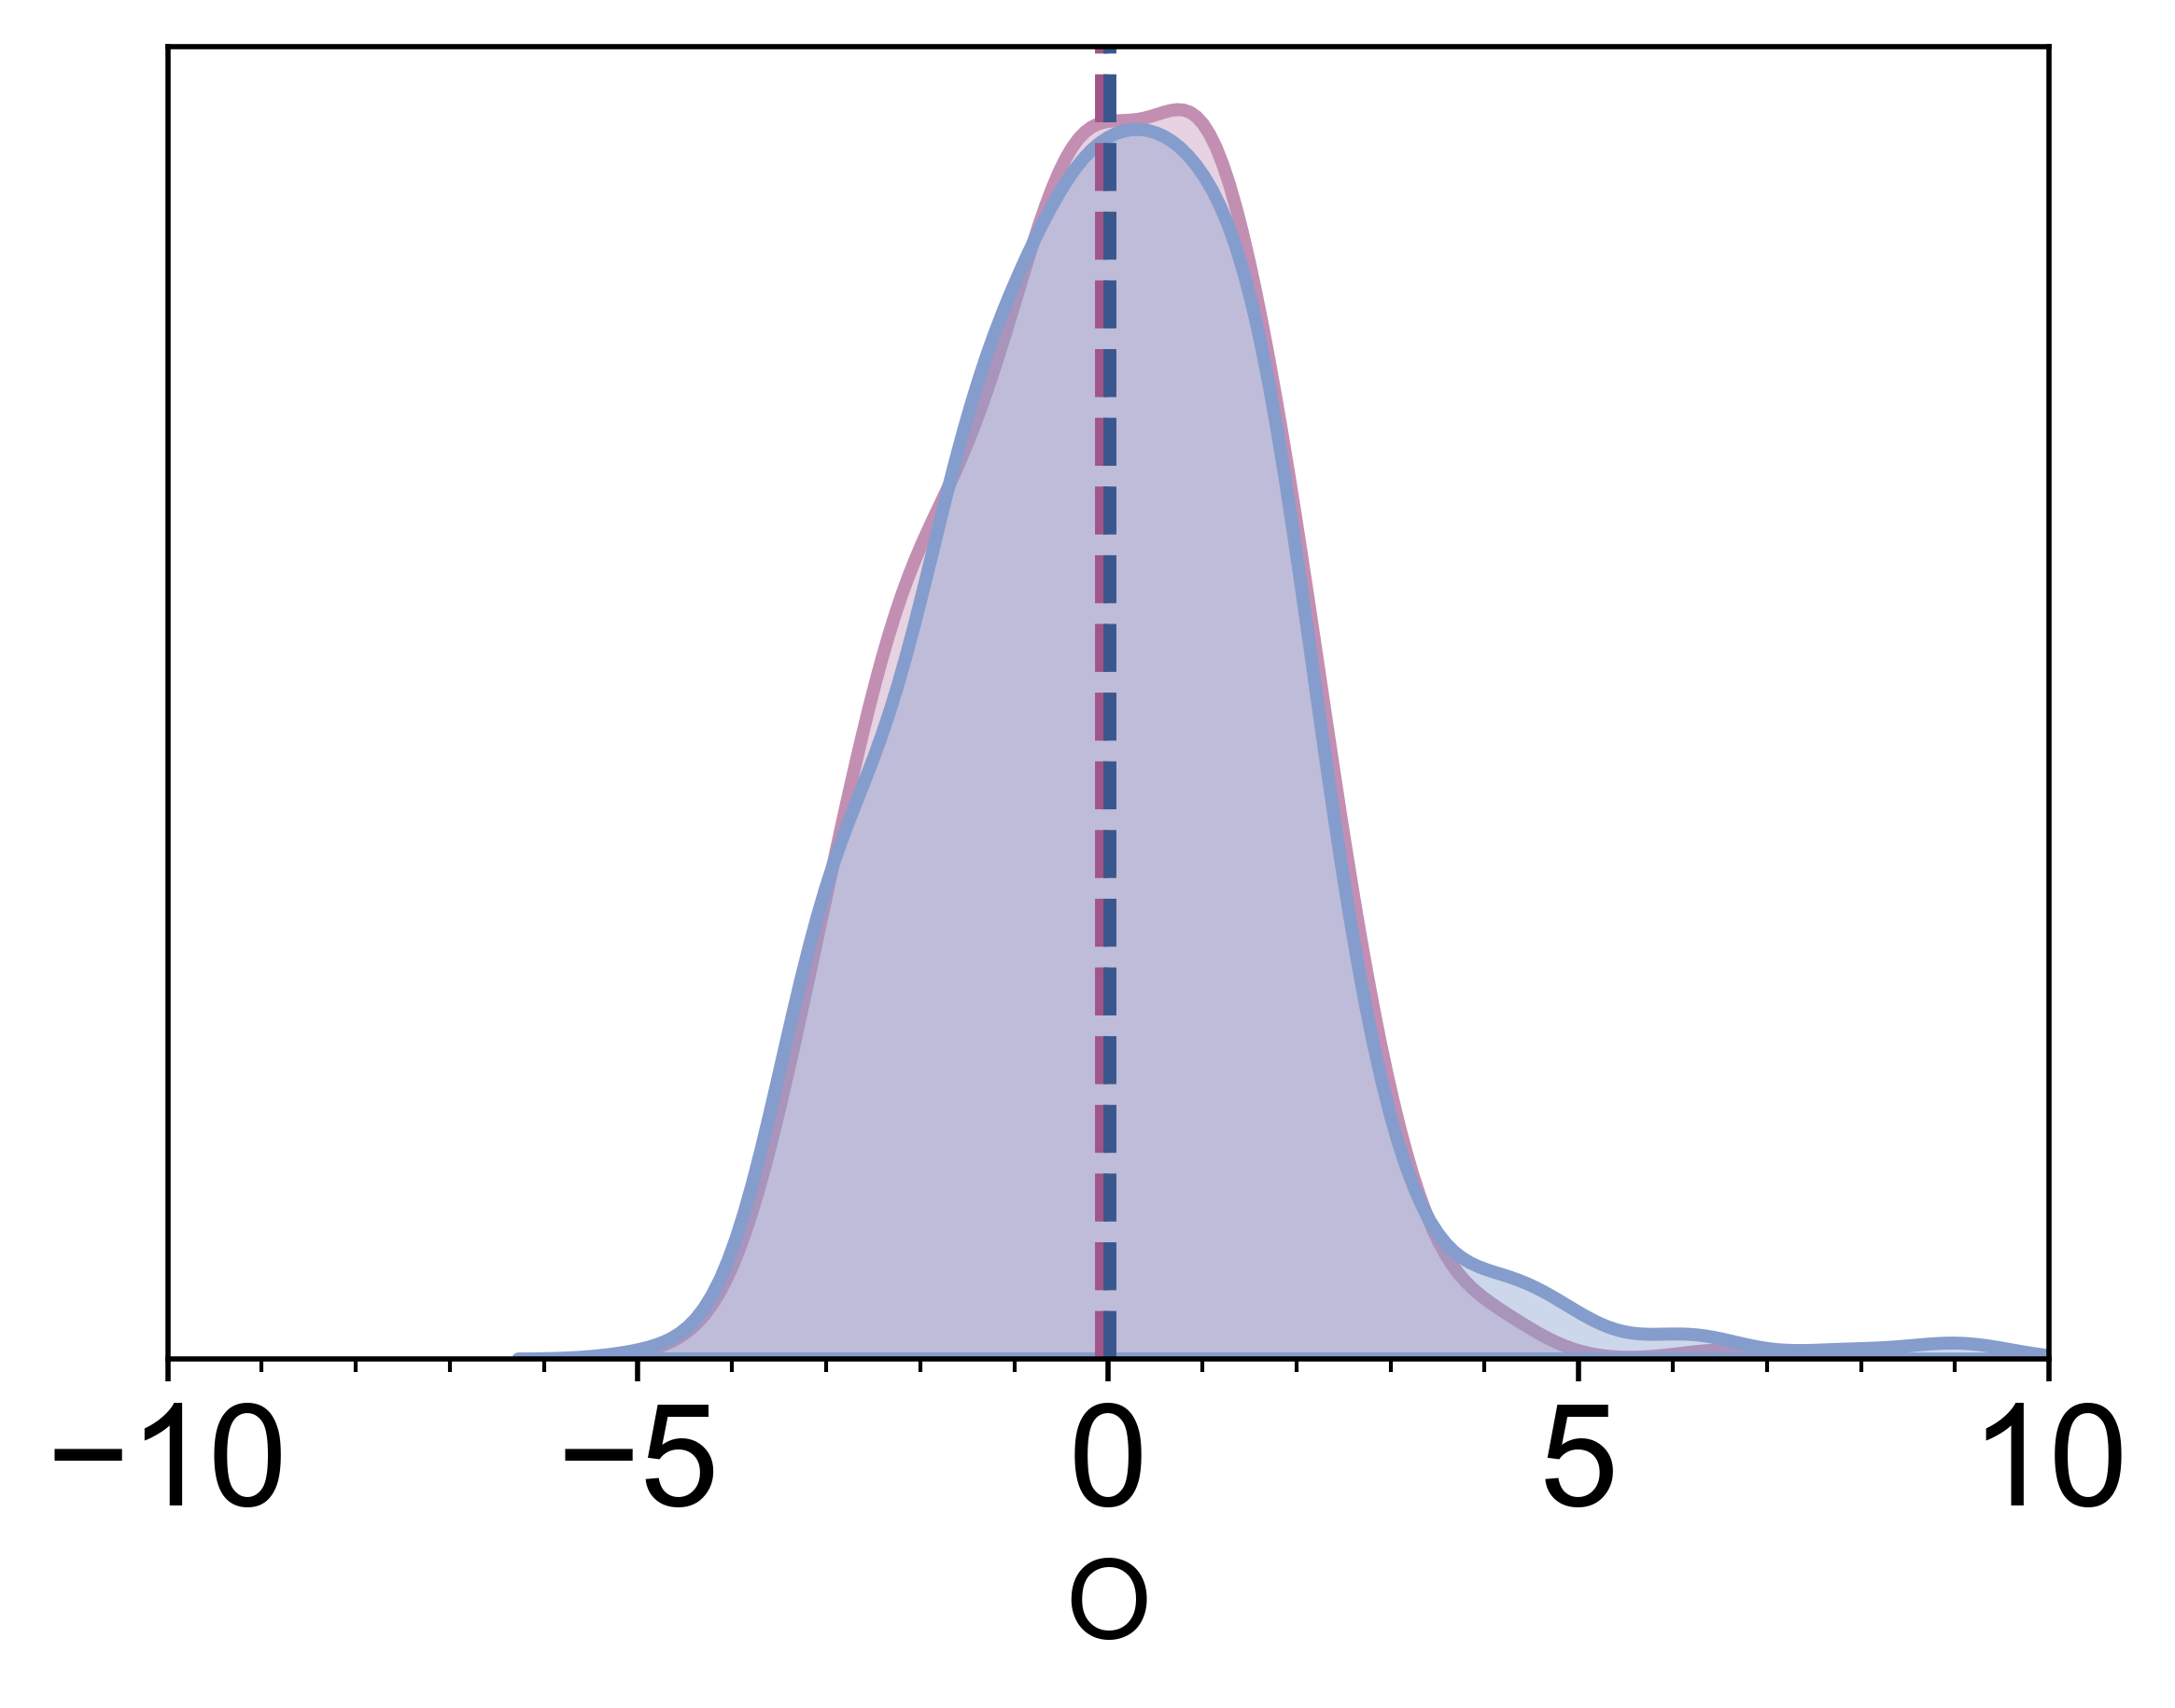

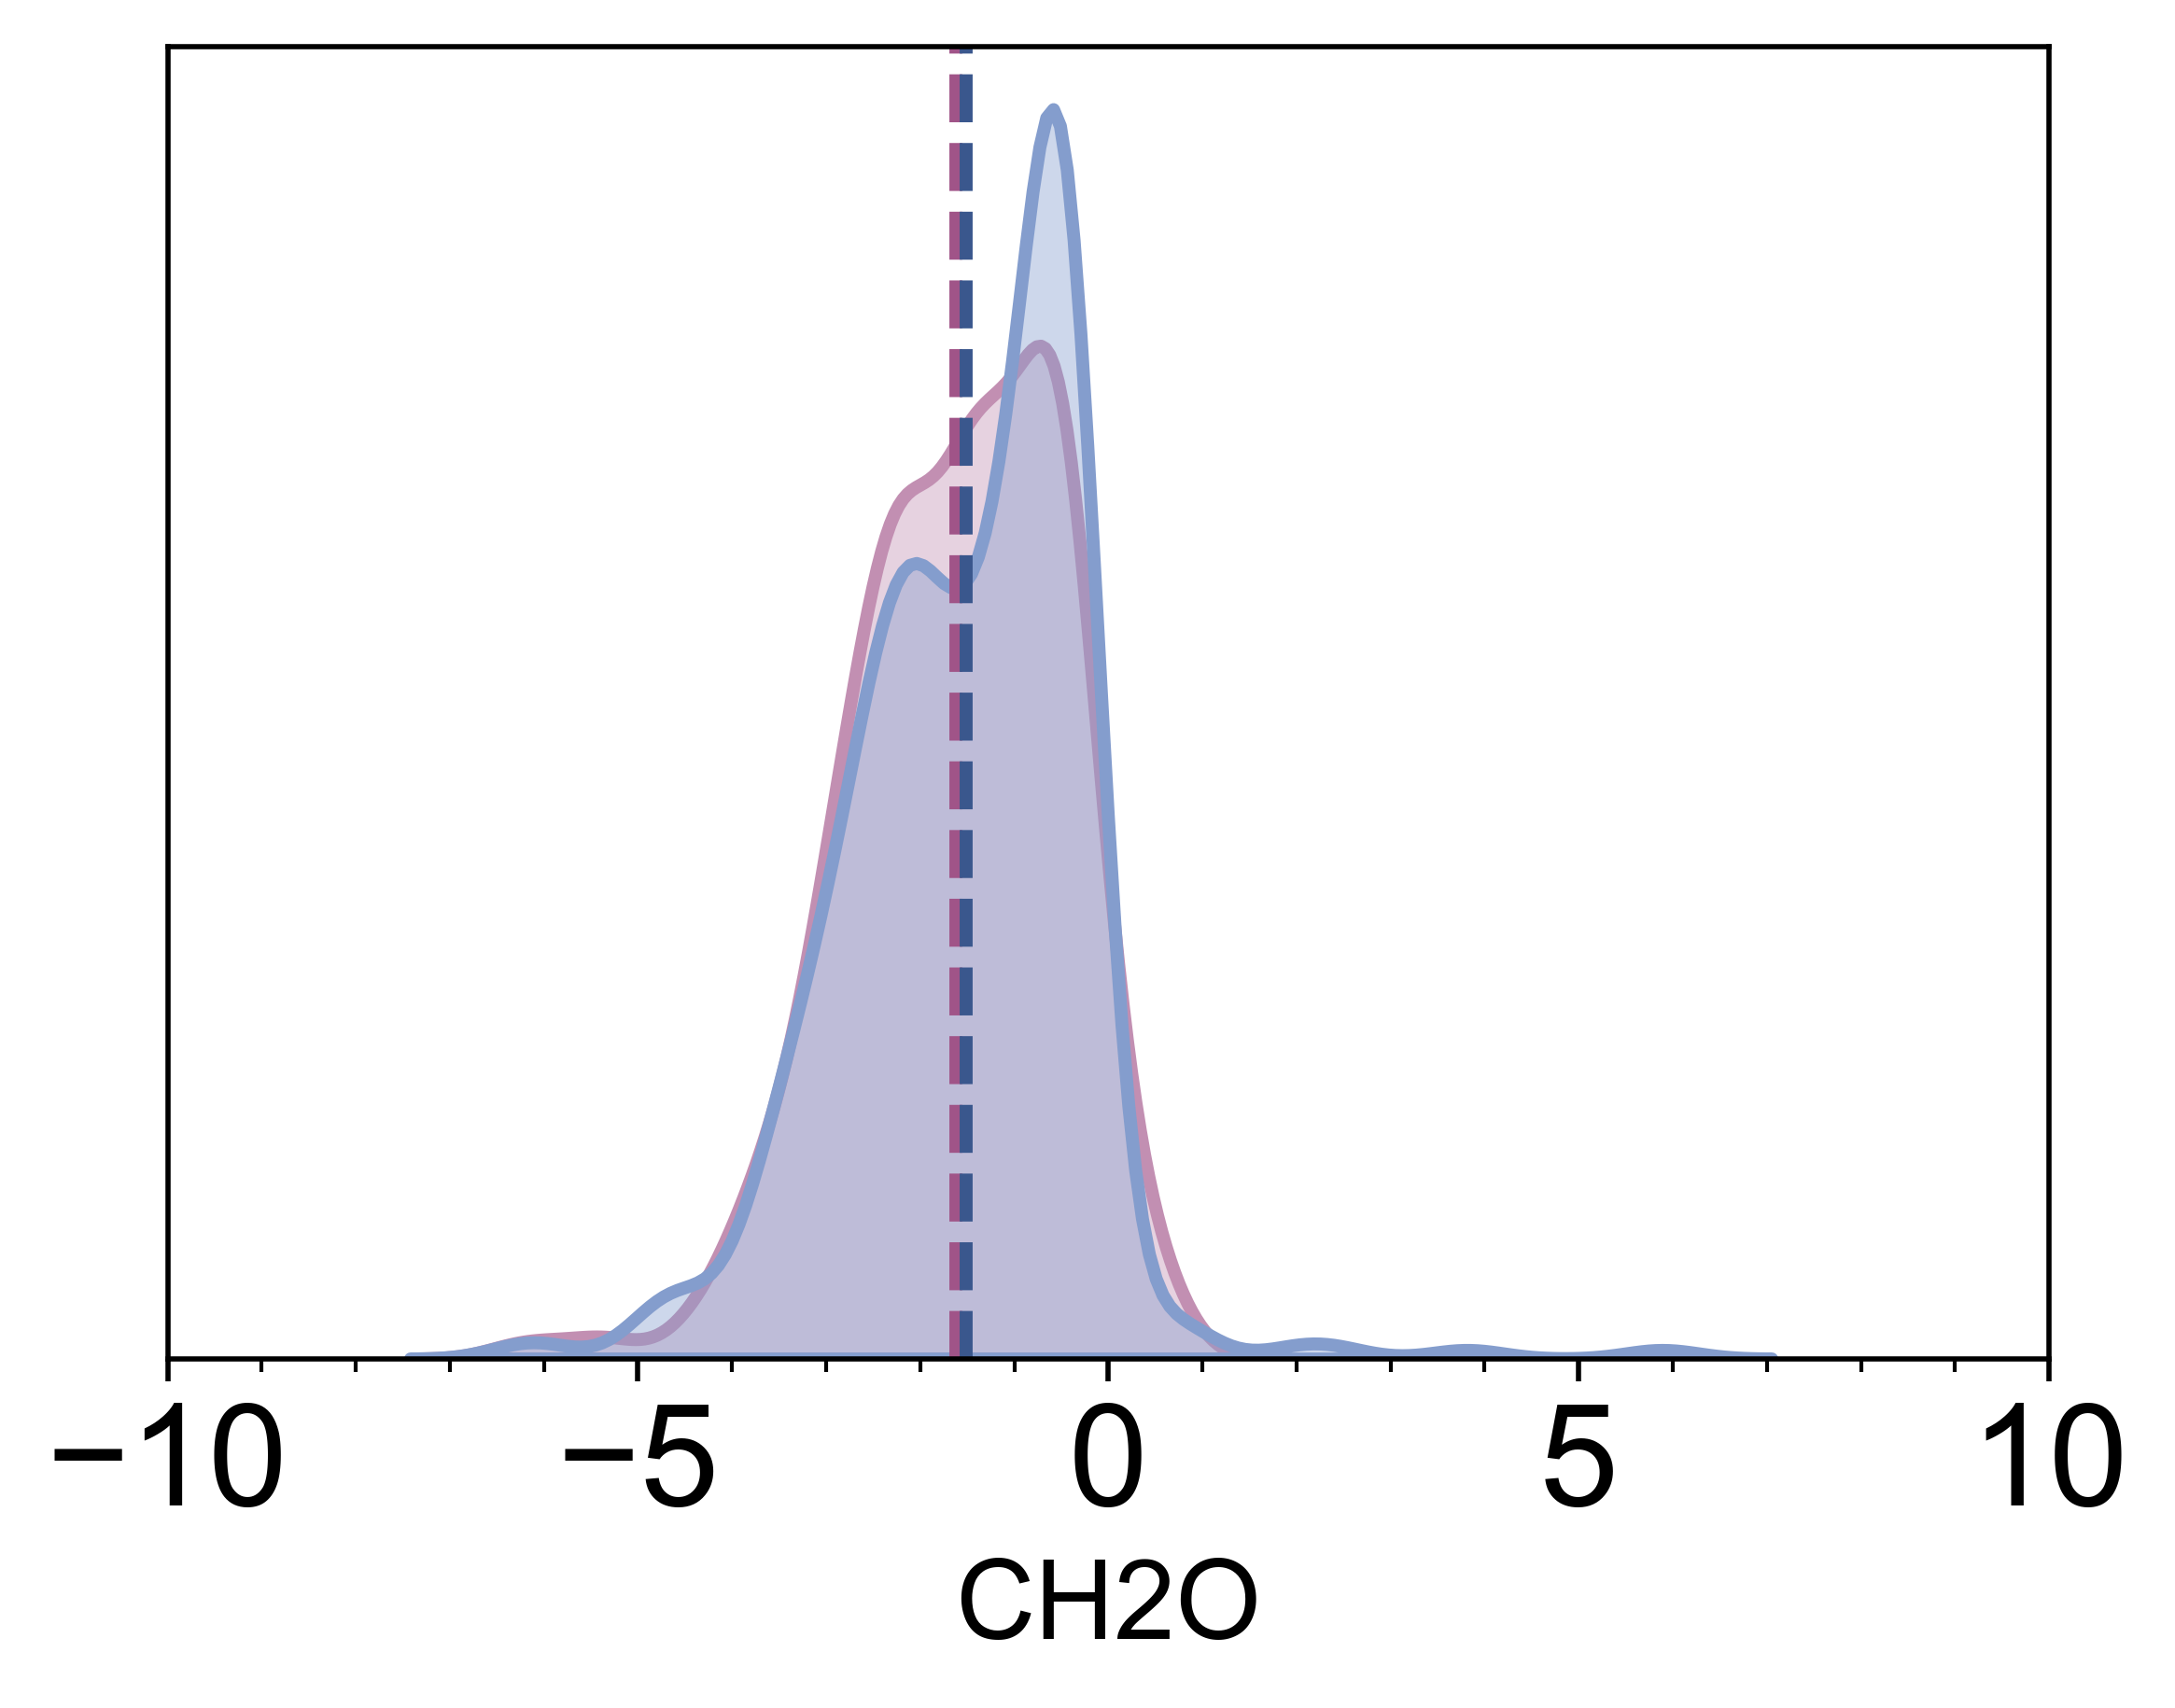

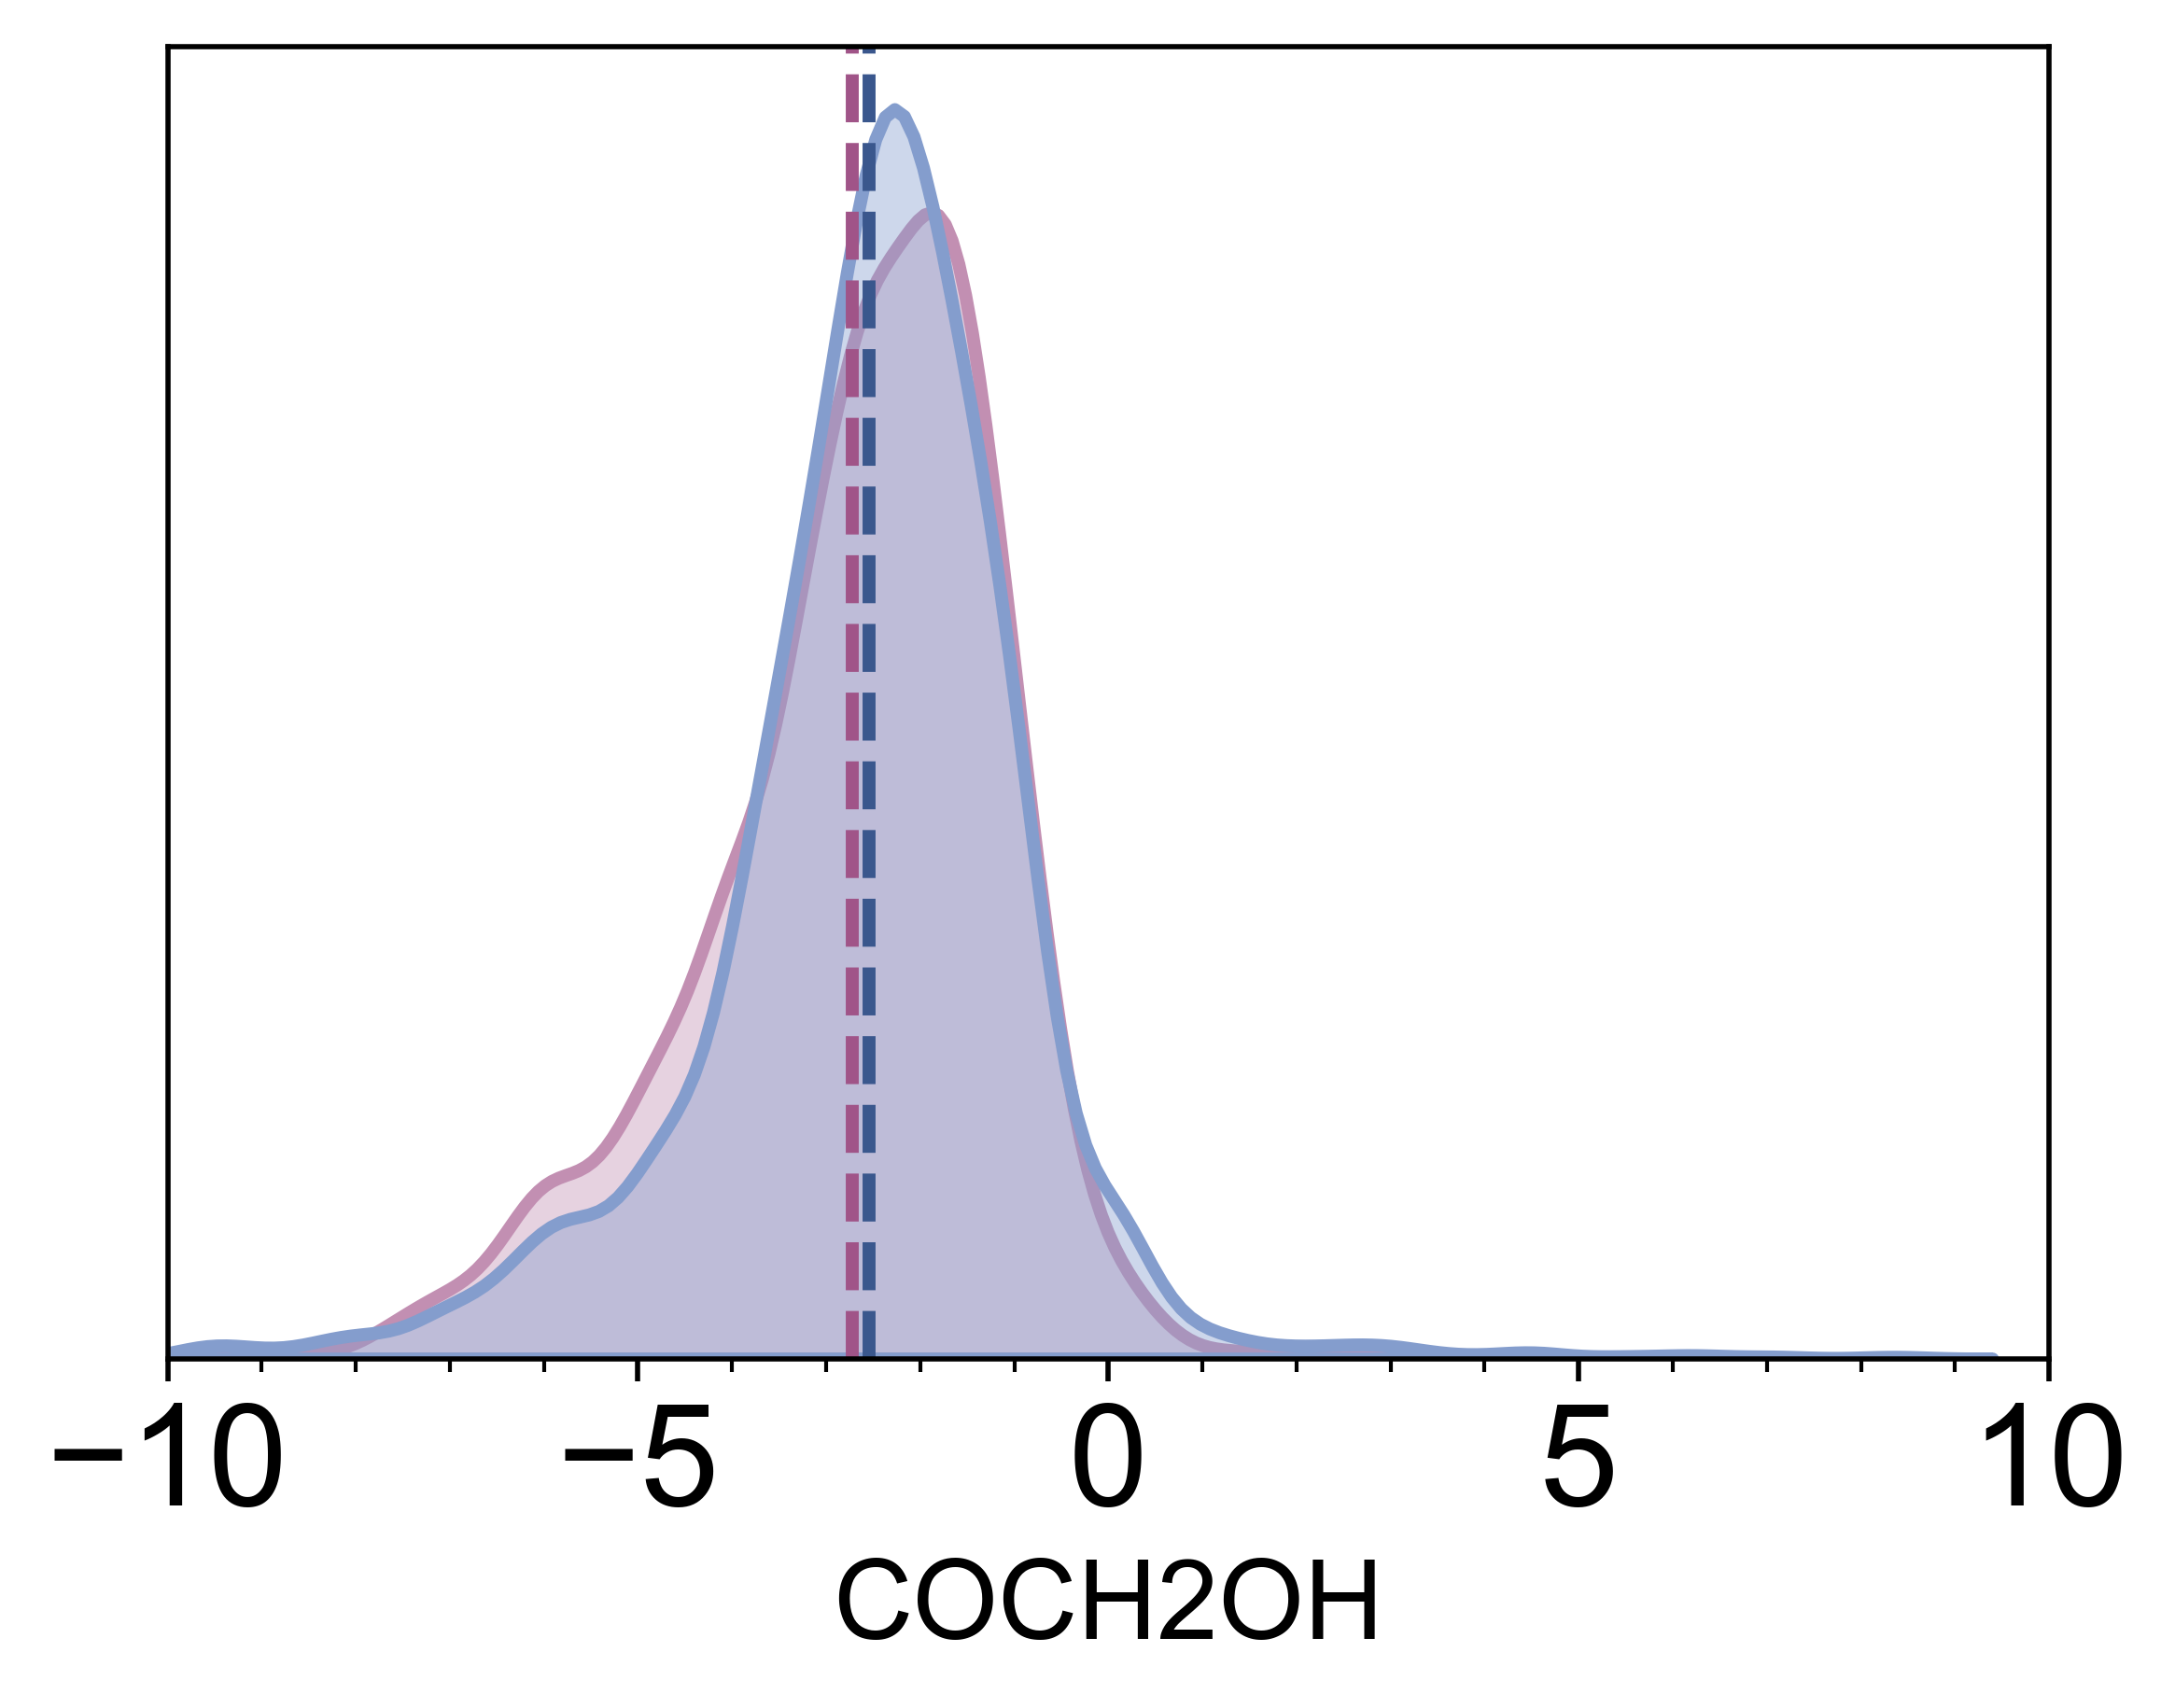

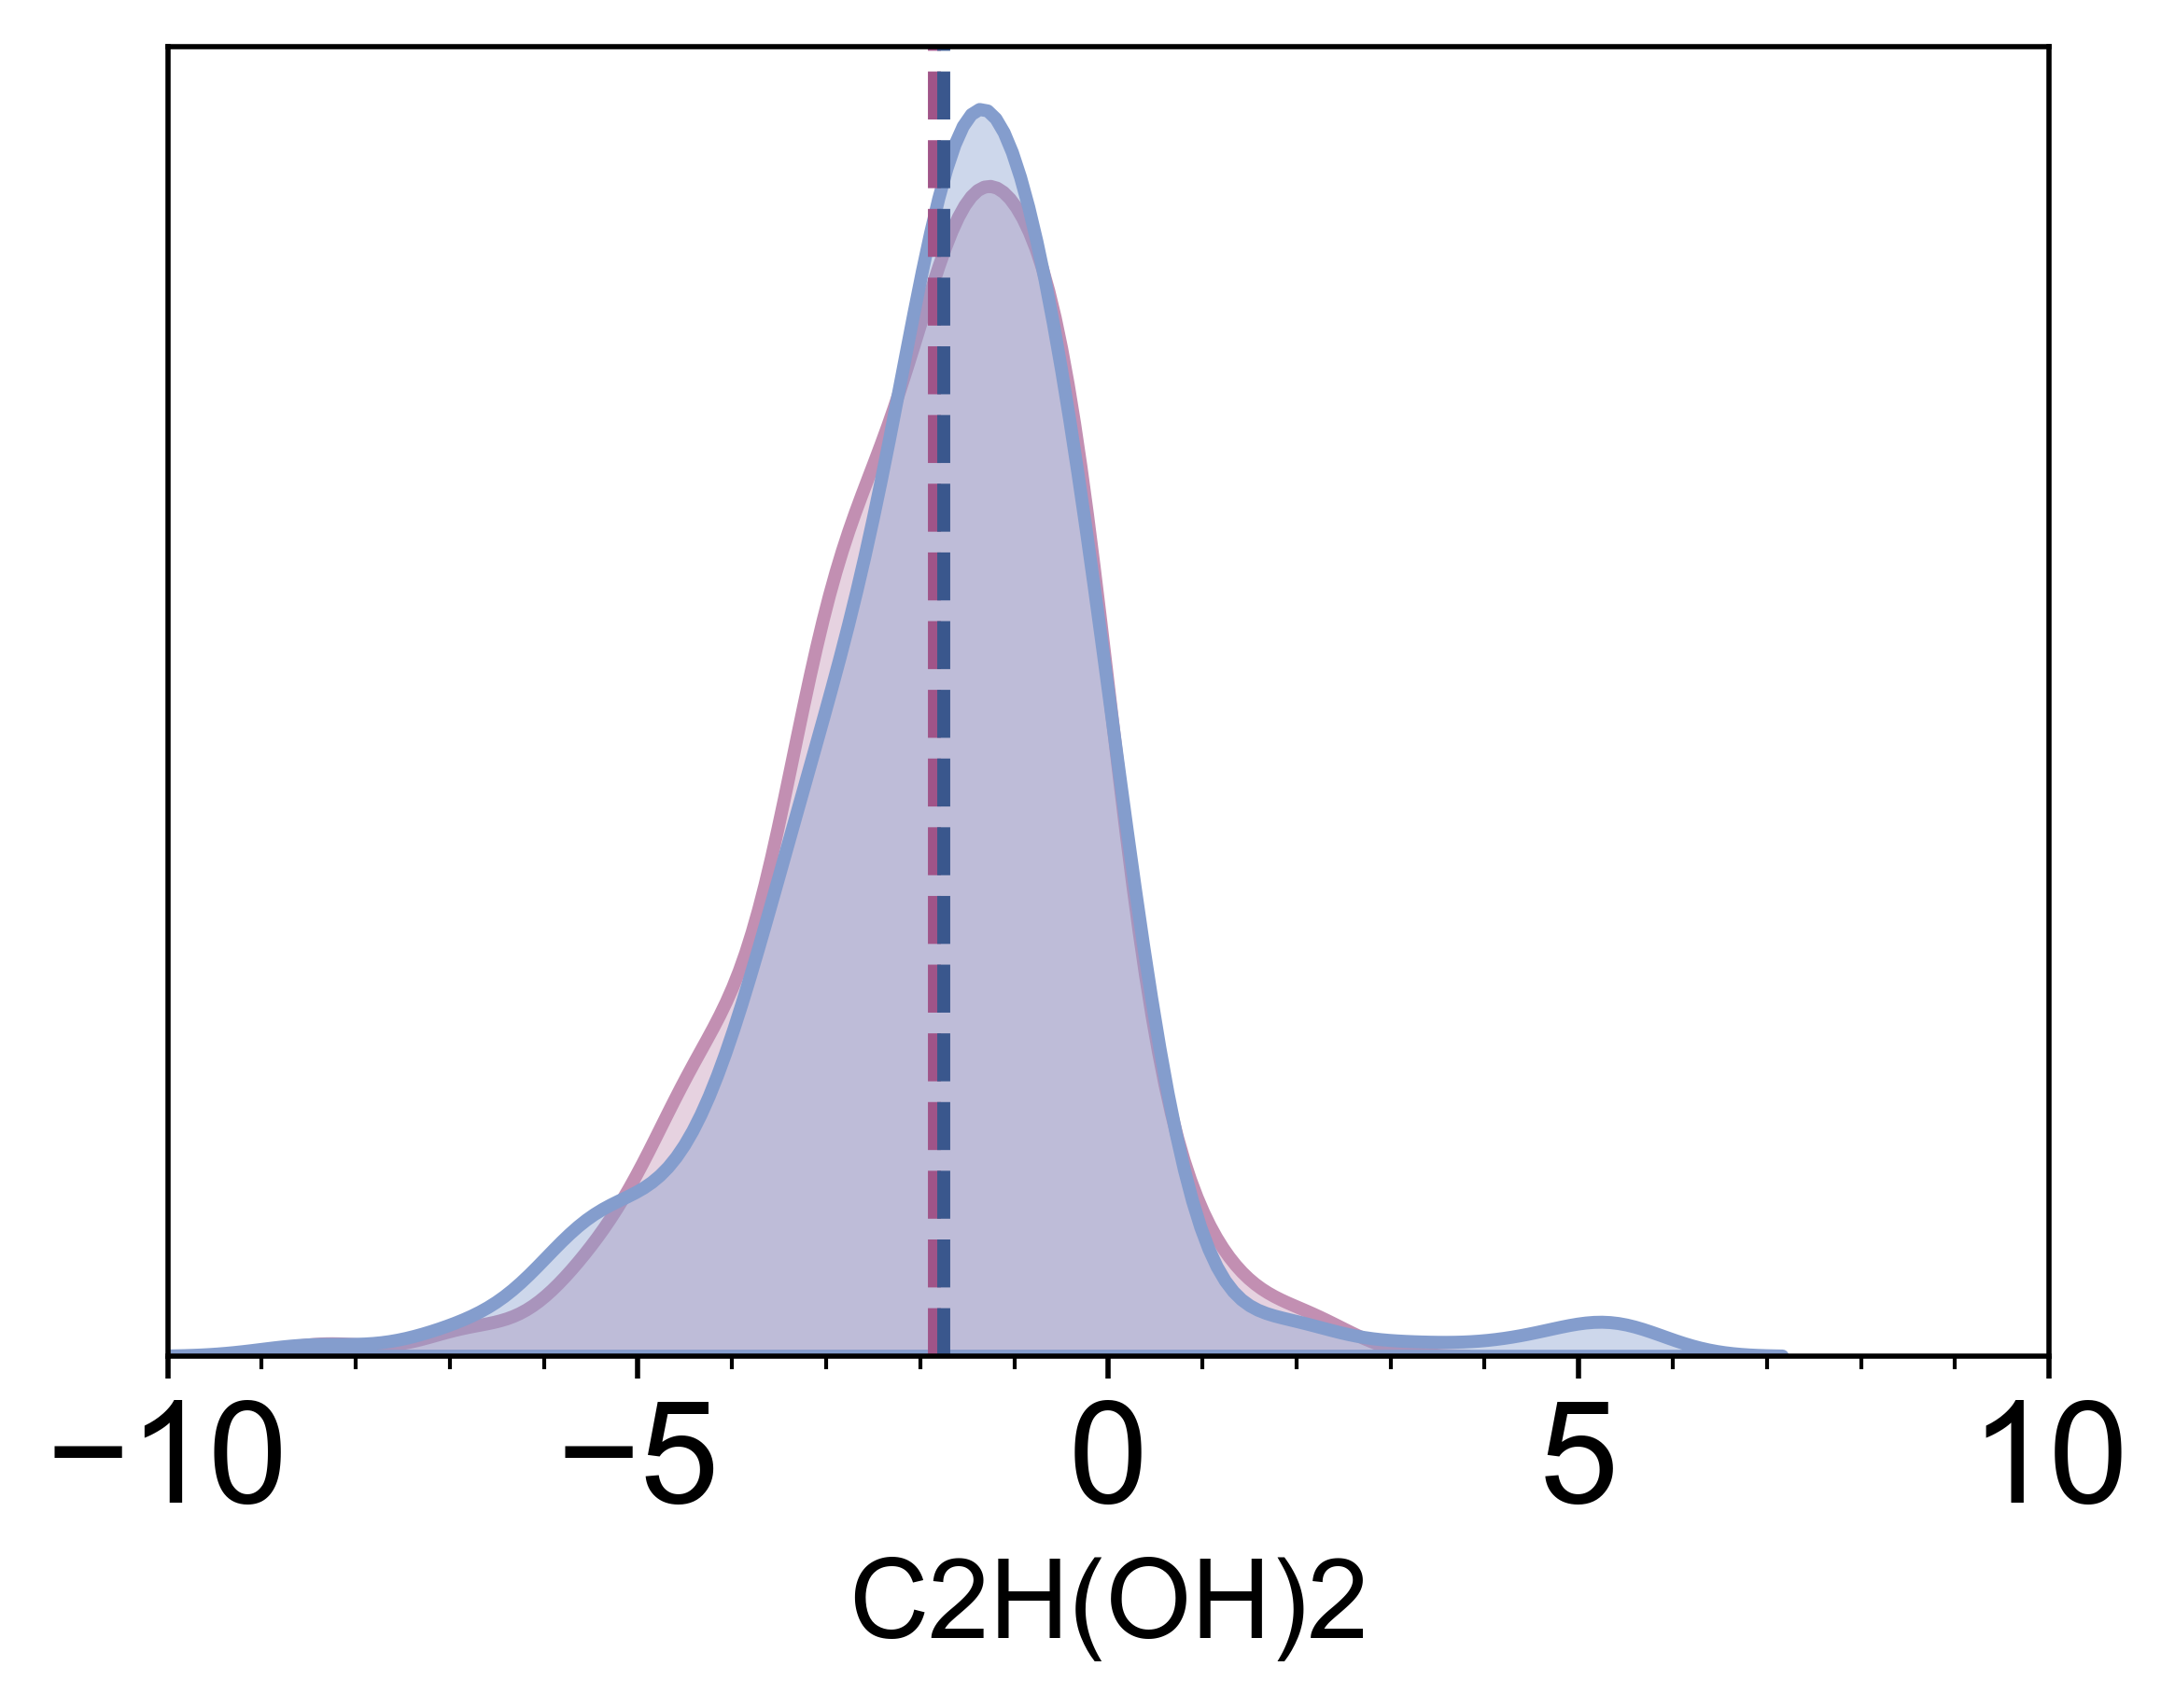

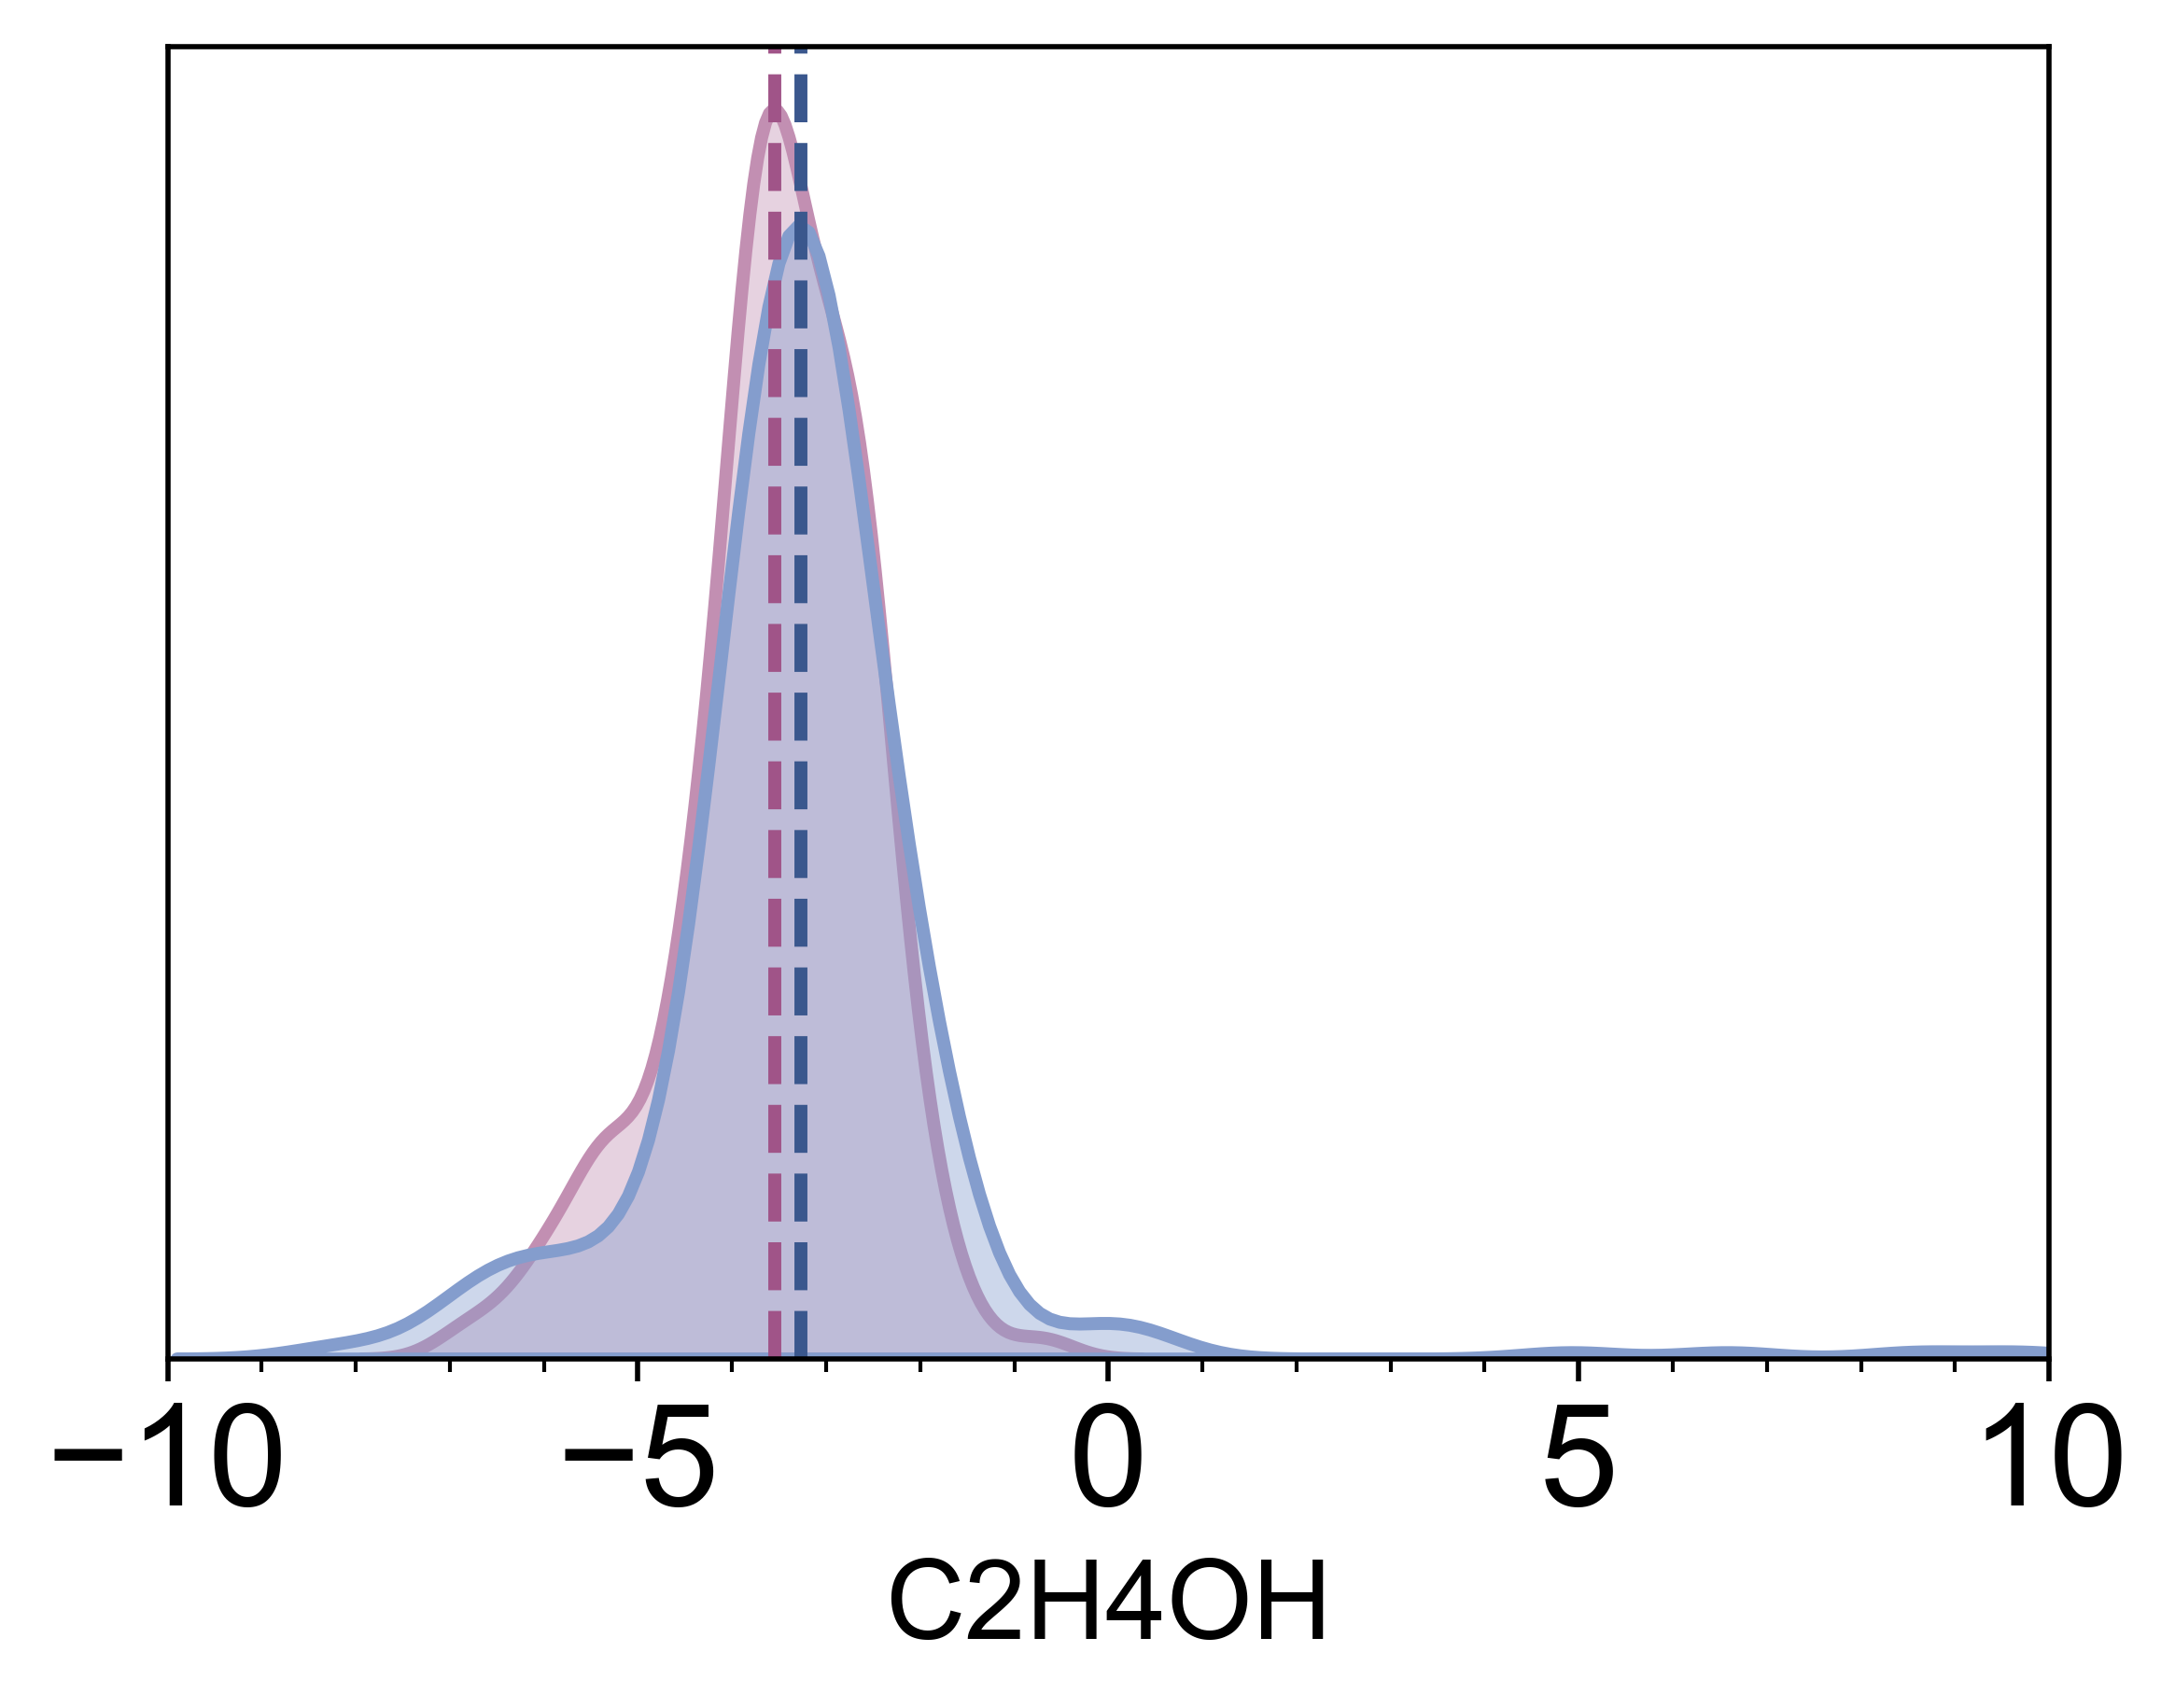

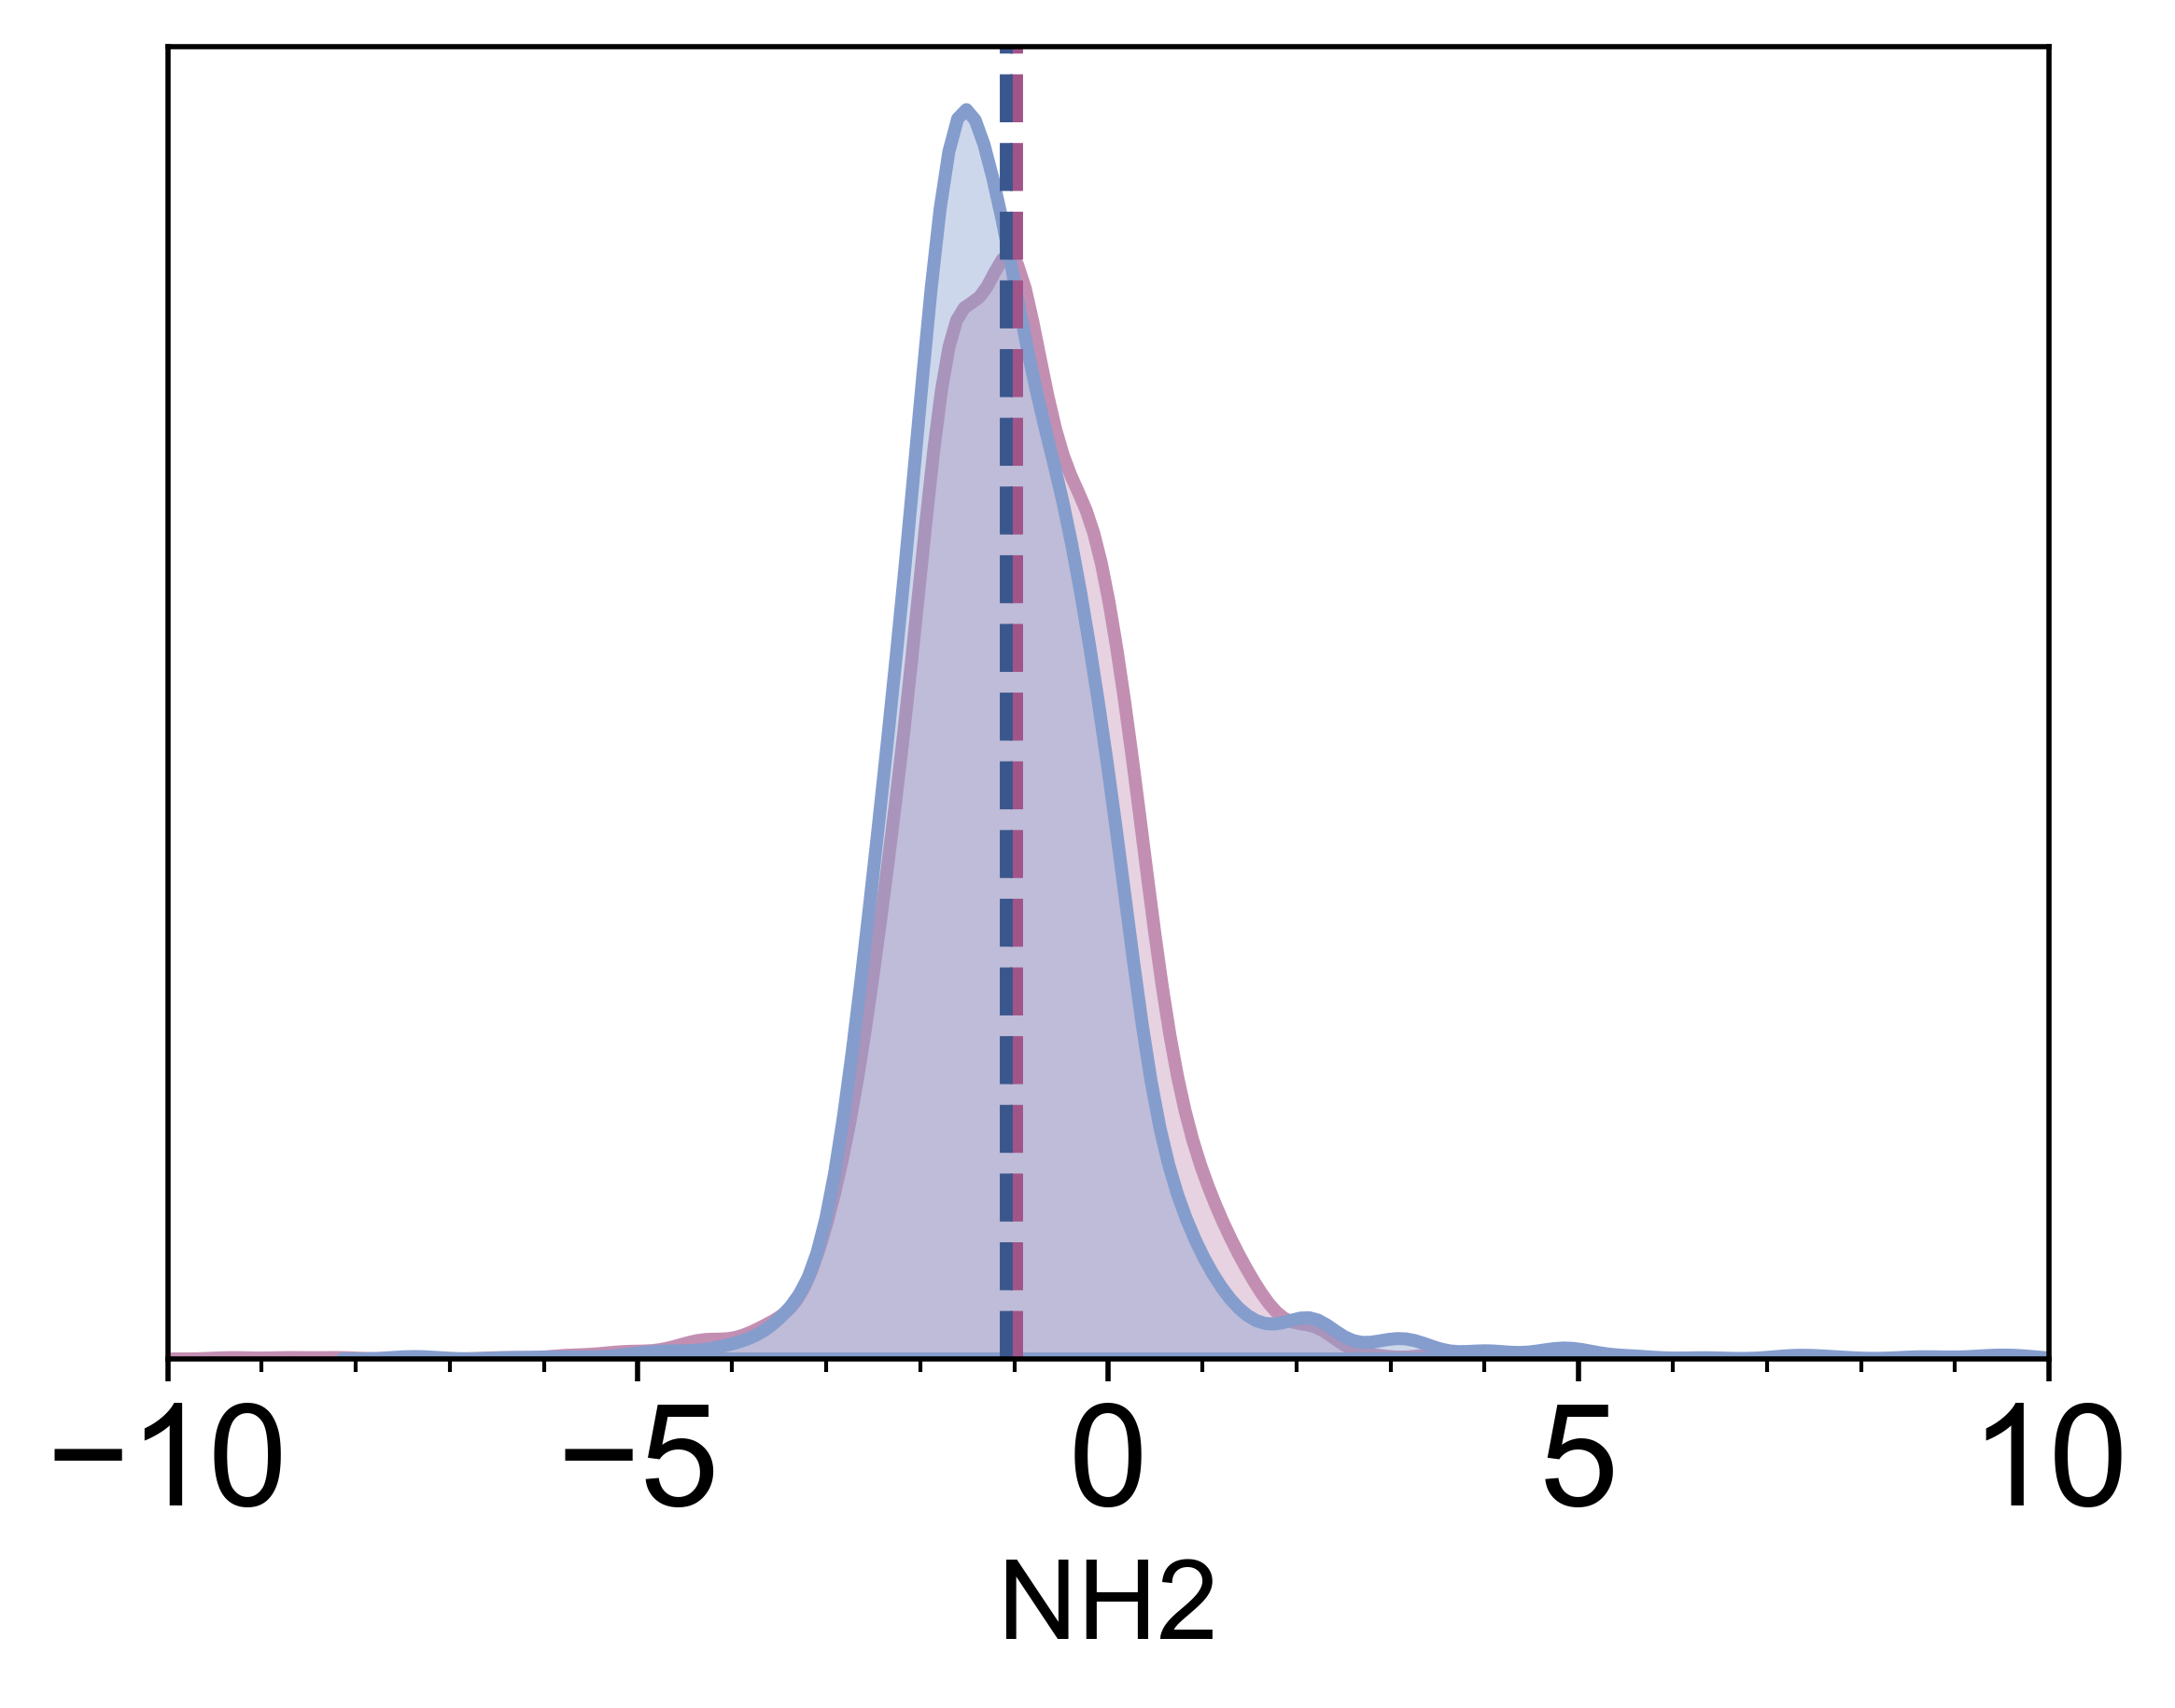

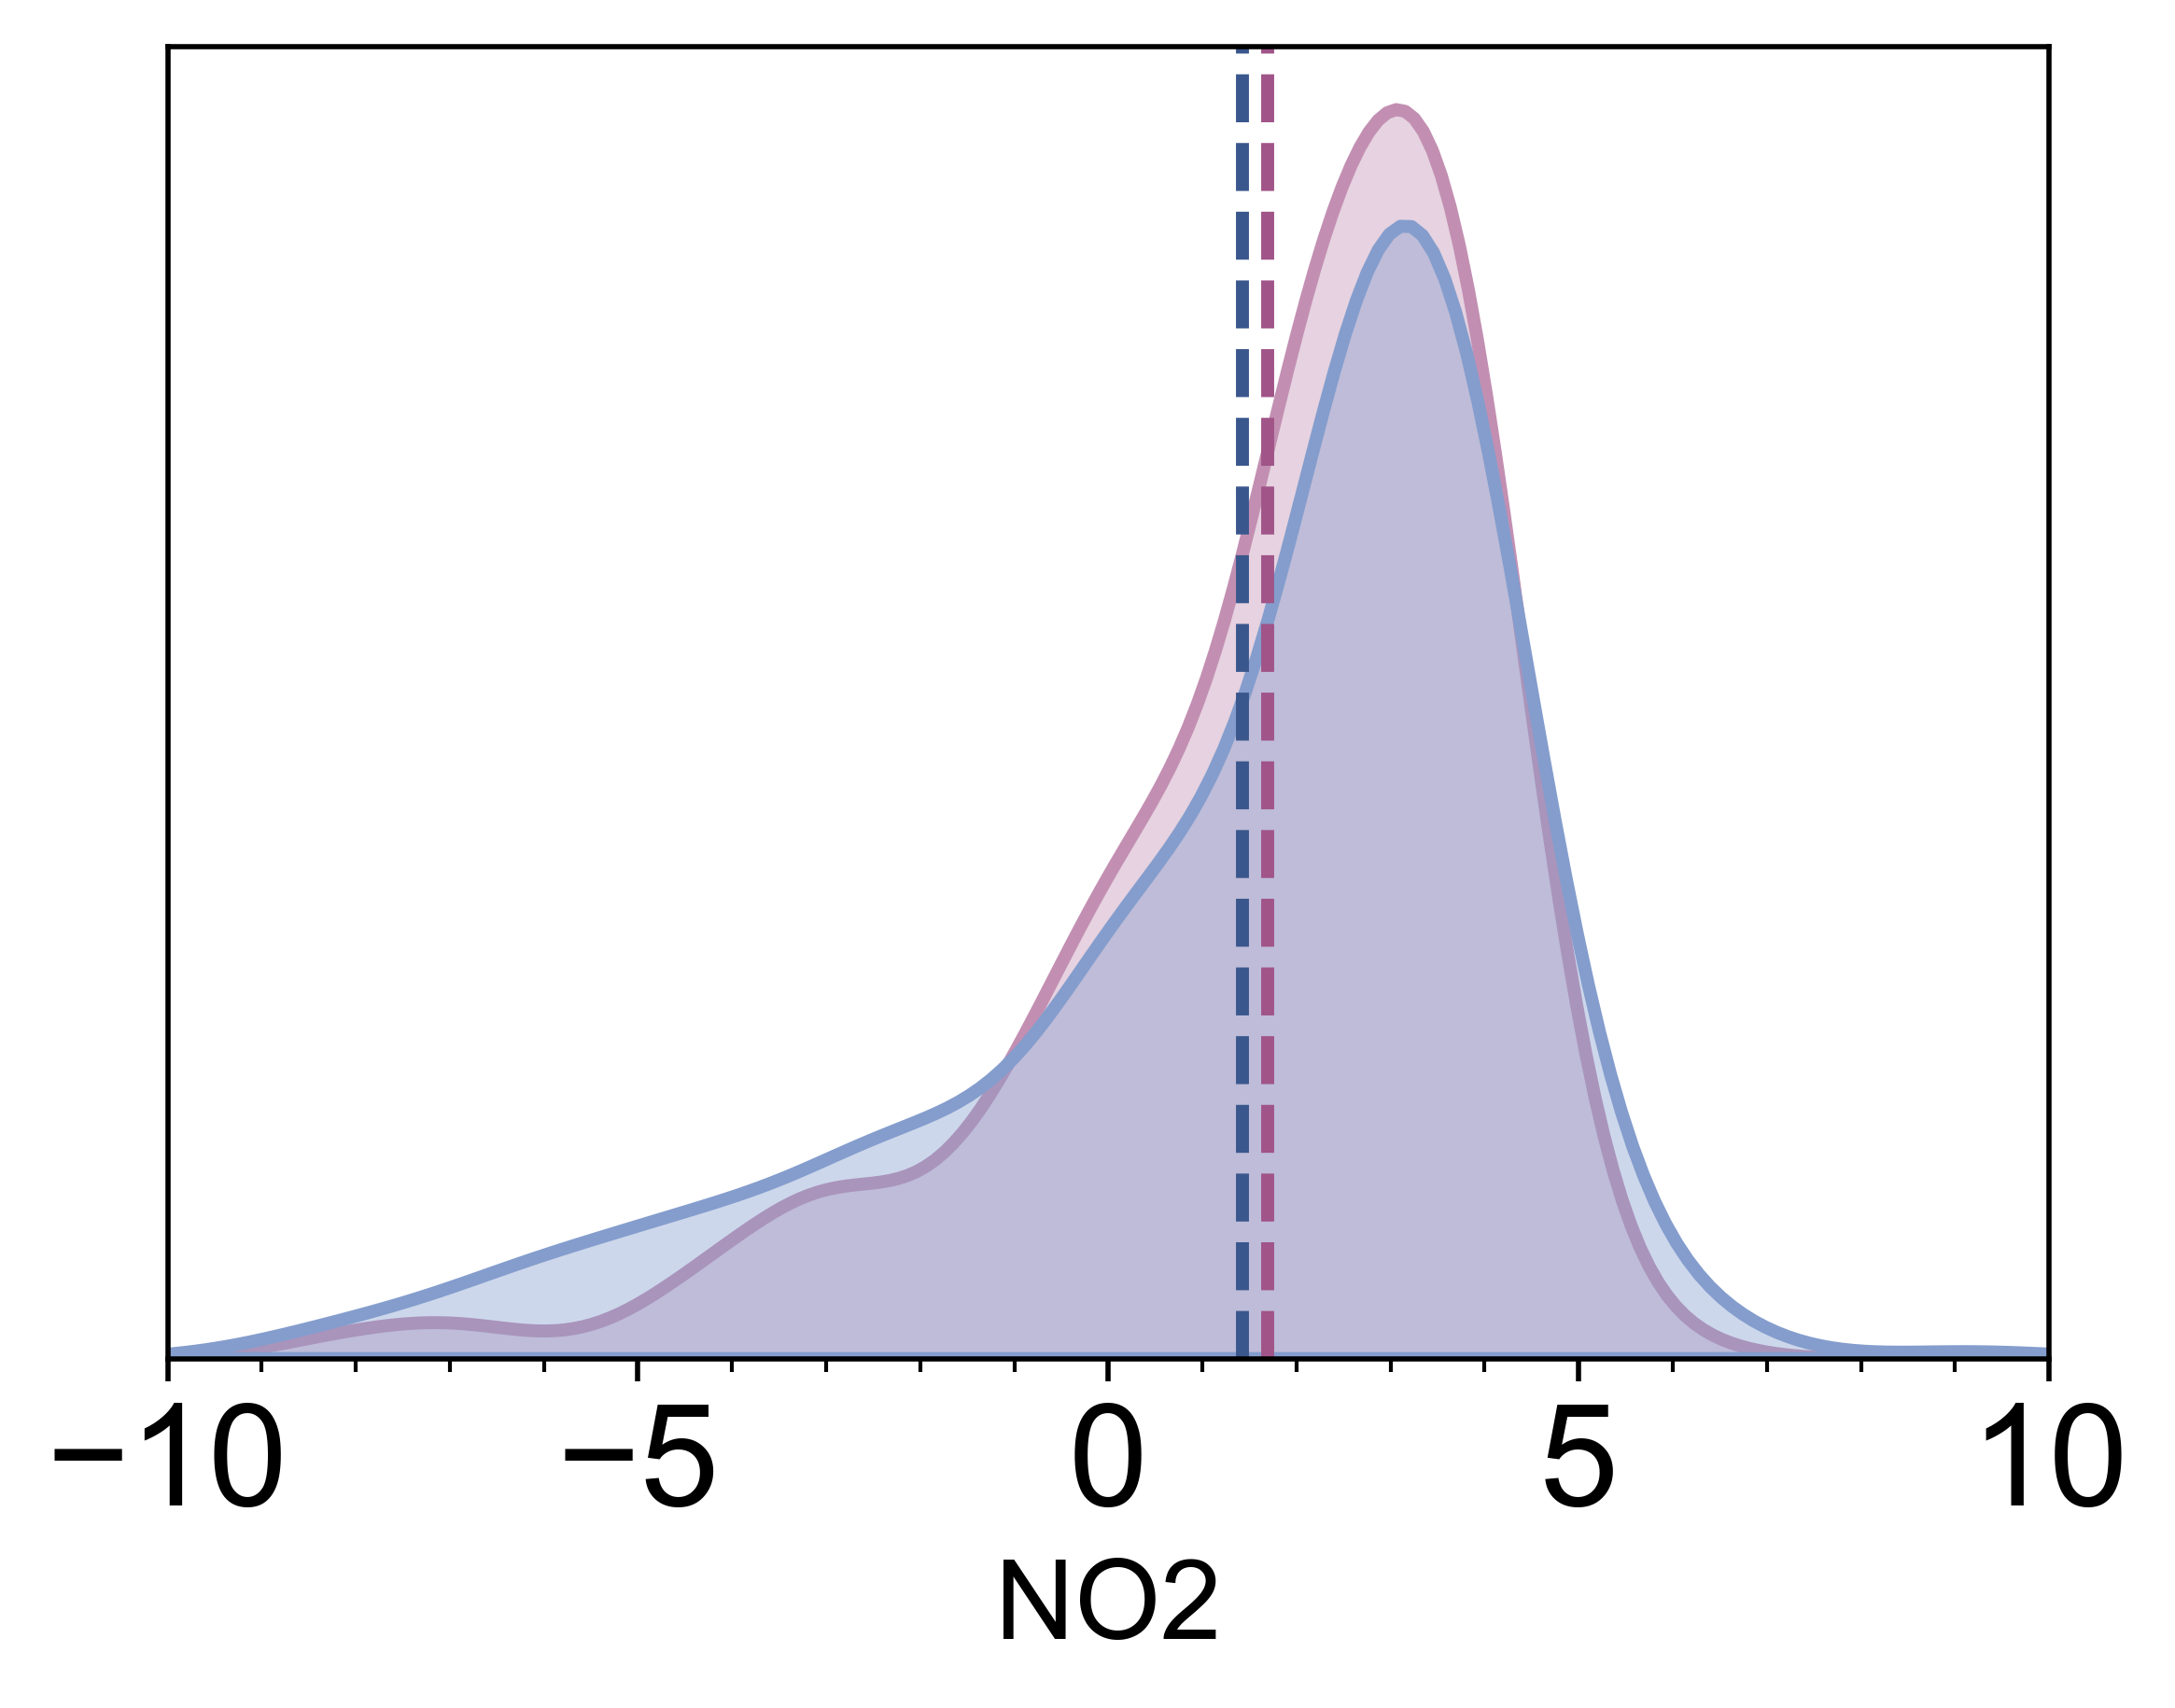

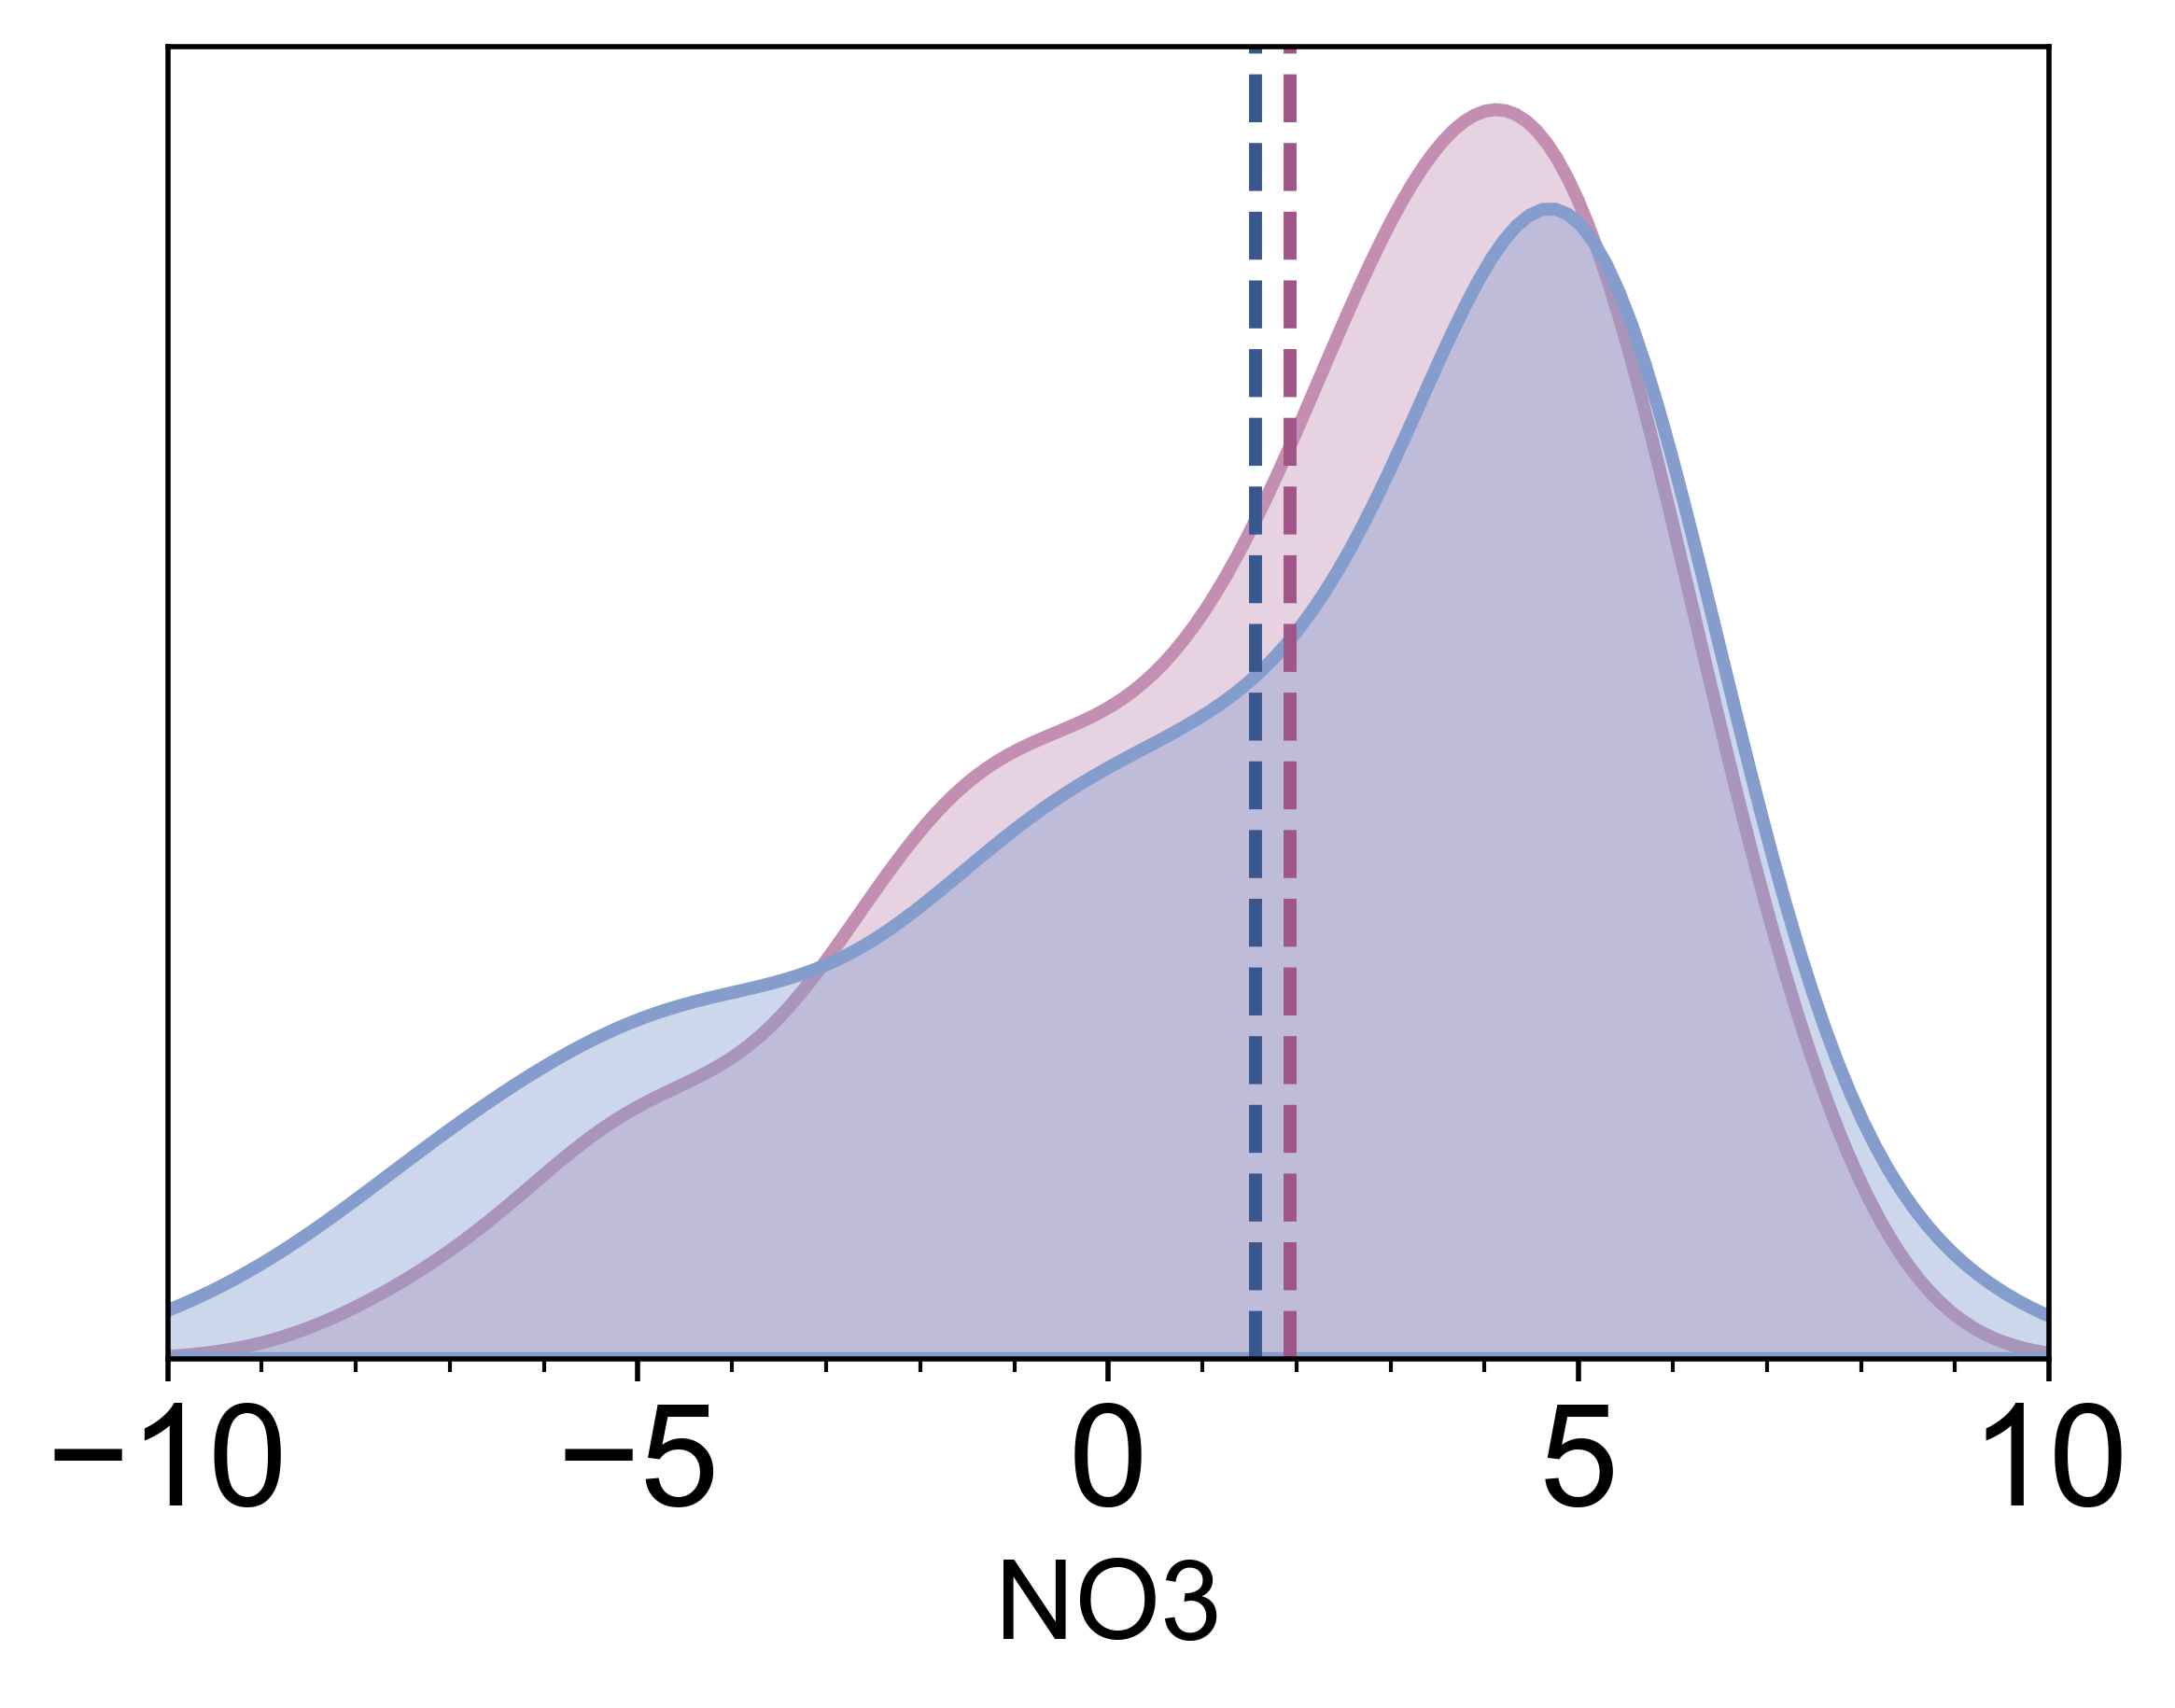

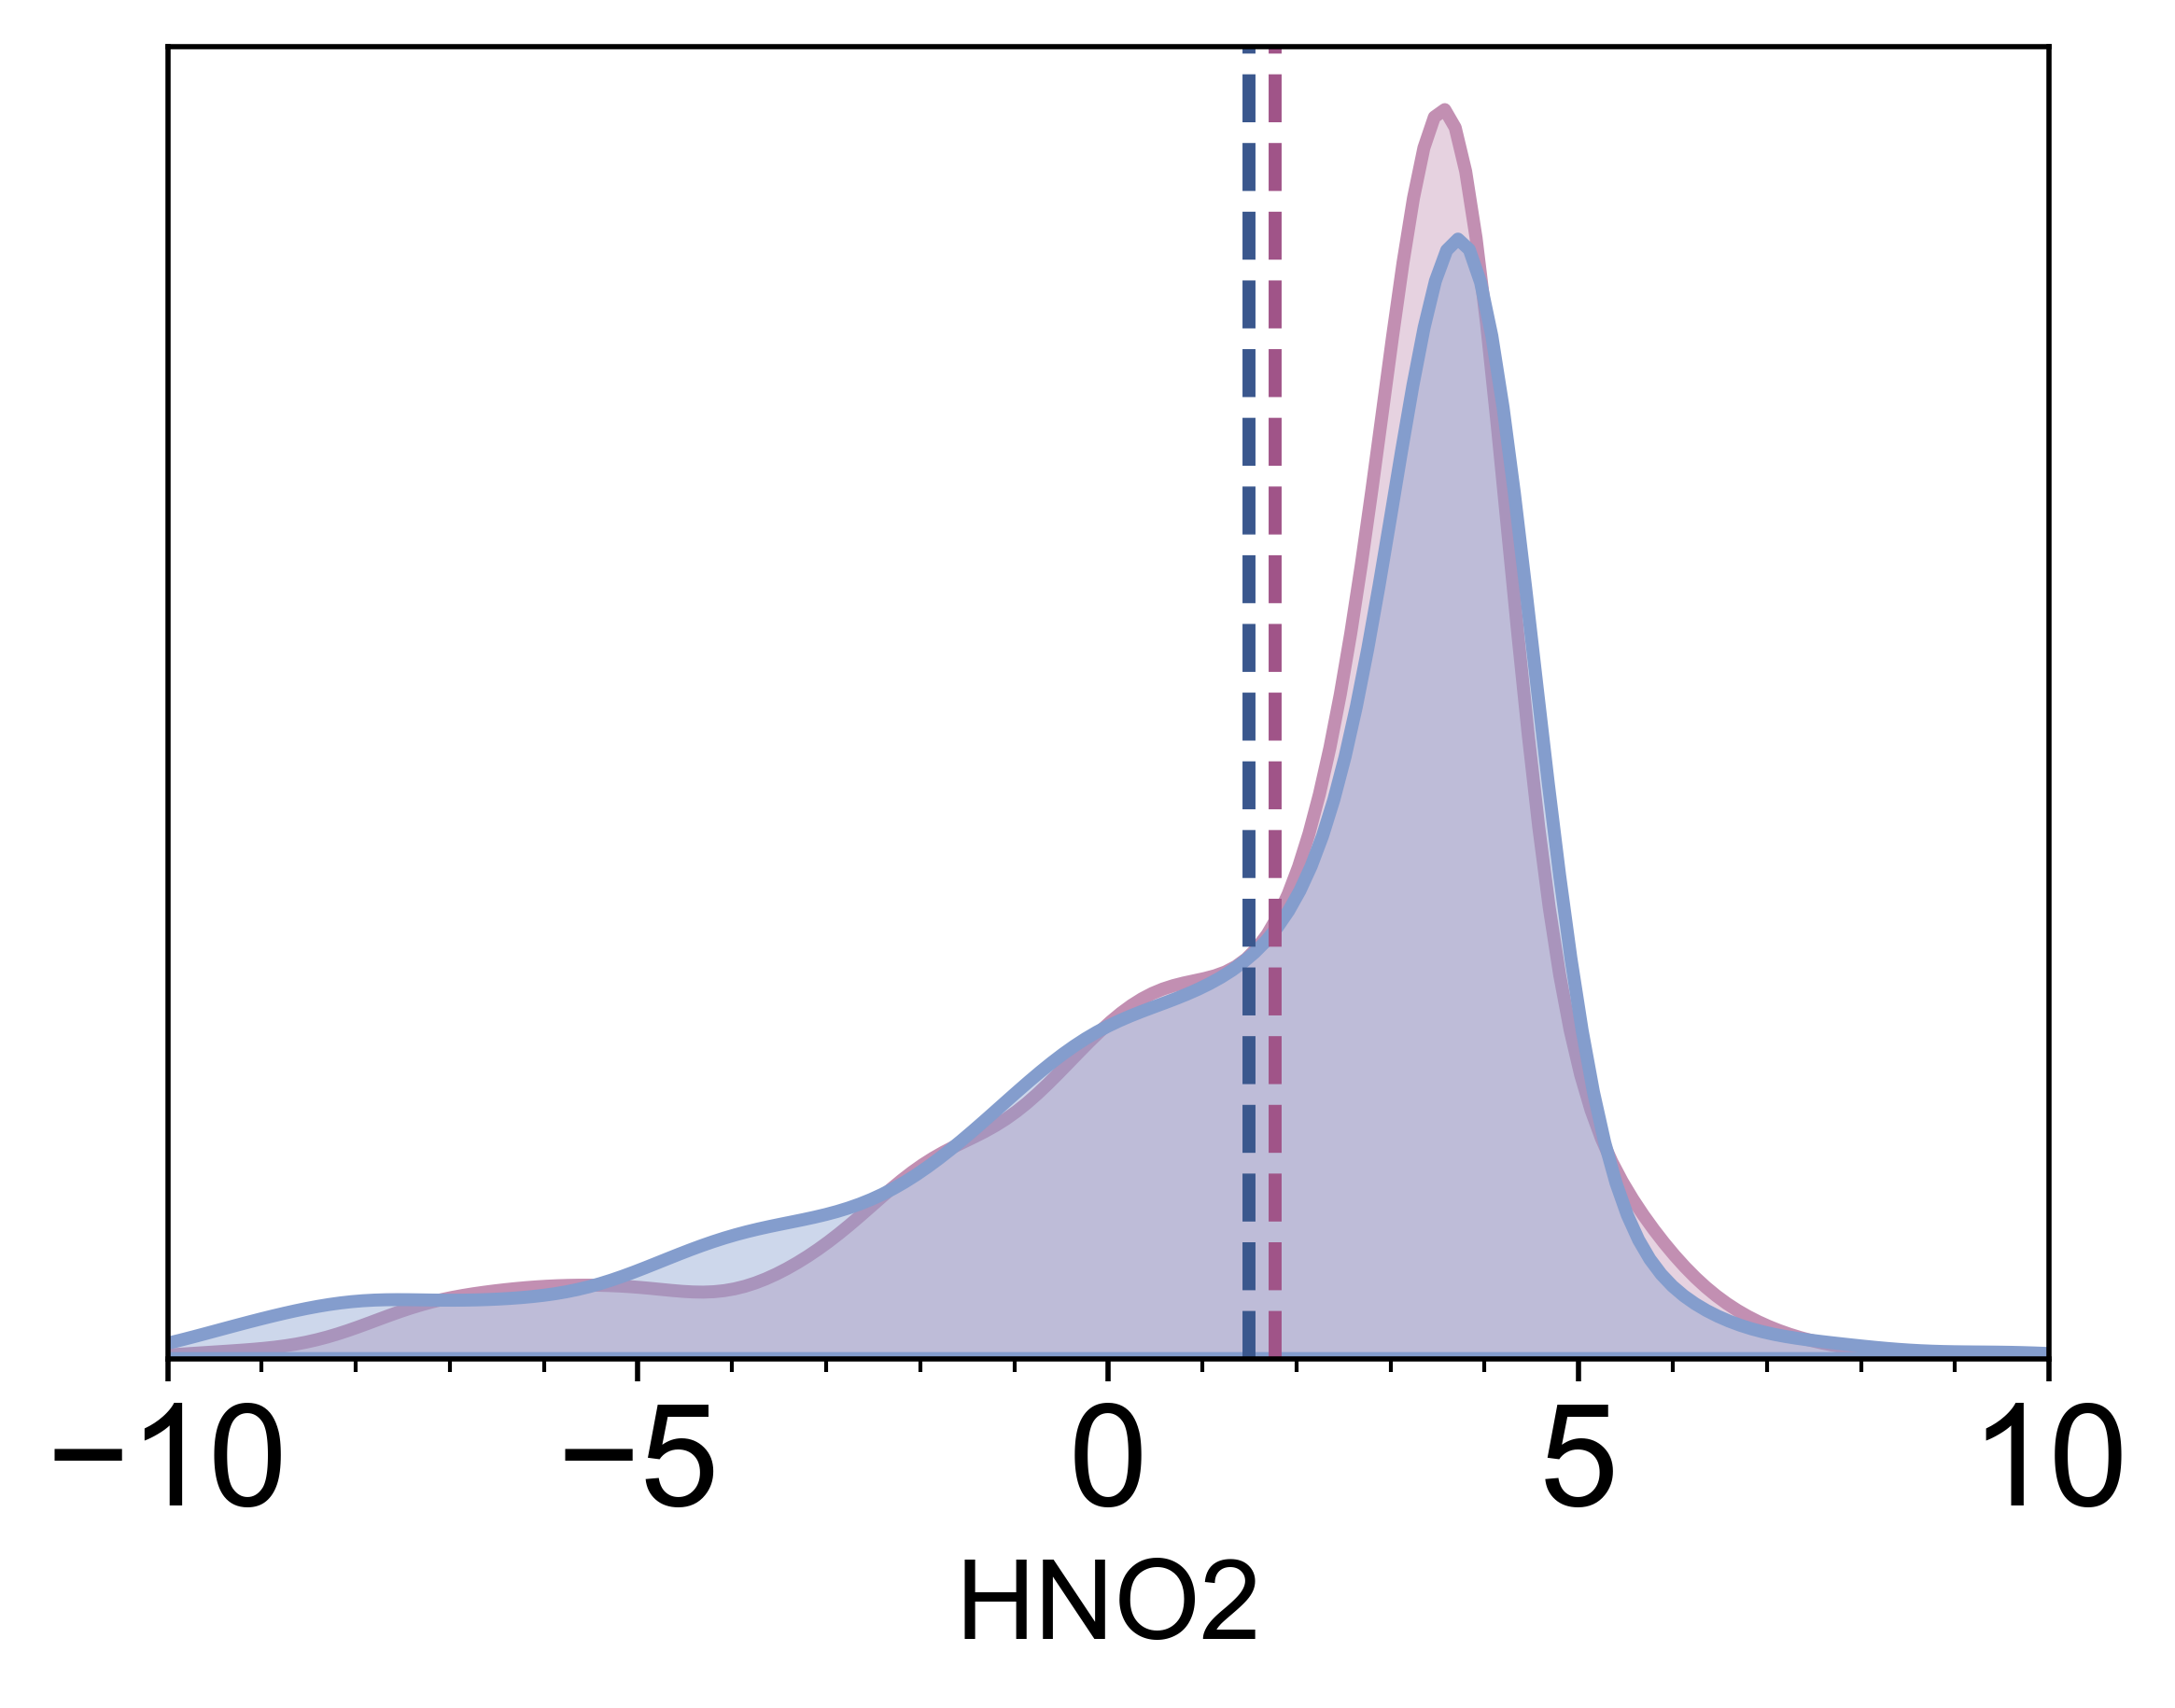

In [7]:
"""
Compare predicted (GACE) vs. reference (dataset) adsorption energies per
adsorbate, via summary stats, Wasserstein distance, and KDE overlay plots.

Setup:
  - DATA_DIR: root folder containing per-adsorbate subfolders
    ("ads_<num>/energies.csv").
  - ads_dict: maps adsorbate name (e.g. "O", "CH2O") -> its numeric ID used
    in file/column naming. Edit this to choose which adsorbates to plot.
  - SELECTED_NUMS: the numeric IDs to iterate over (all values of ads_dict).
  - FILTER_RANGE = (-10, 10): energy bounds (eV) used to discard outlier rows.
  - XLIM = (-10, 10): x-axis limits for the energy distribution plots.

For each adsorbate ID in SELECTED_NUMS:
  1. Loads "{DATA_DIR}/ads_{num}/energies.csv", which contains a GACE-predicted
     adsorption energy column ("ads_{num}_adsorption_E") and a reference/
     target energy column ("ads_{num}_target_E").
  2. Filters out rows where either column falls outside FILTER_RANGE
     (i.e. keeps only energies within ±10 eV).
  3. Looks up the adsorbate's short name (`key`) from ads_dict via its ID.
  4. Computes mean/std of the dataset and GACE energy columns, and the
     Wasserstein (earth mover's) distance between the two distributions.
  5. Prints per-adsorbate summary stats: number of dropped rows, dataset
     mean ± std, GACE mean ± std, and the Wasserstein distance.
  6. Plots overlaid KDEs of the dataset vs. GACE energy distributions
     (filled, semi-transparent), with dashed vertical lines marking each
     distribution's mean.
  7. Formats the axes (minor ticks on, x-limits set to XLIM, y-axis hidden
     since only the density shape matters), labels the x-axis with the
     adsorbate name, and saves the figure as an SVG to
     "fig2/panel/{key}.svg" via `save_flat_svg`.
"""

DATA_DIR = "./data/oc20_and_gace/energy_data"

# ---- EDIT THIS to pick which datasets to plot ----
ads_dict = {"O": 0, "CH2O": 10, "COCH2OH": 41, "C2H(OH)2": 42, "C2H4OH": 54, "NH2": 71, "NO2": 75, "NO3": 78, "HNO2": 80}
SELECTED_NUMS = list(ads_dict.values())

# Discard any row where either column falls outside this range.
FILTER_RANGE = (-10, 10)

XLIM = (-10, 10)


abs_errors = {}
target_vals = {}
computed_vals = {}
for num in SELECTED_NUMS:
    path = f"{DATA_DIR}/ads_{num}/energies.csv"
    df = pd.read_csv(path)

    gace_col = f"ads_{num}_adsorption_E"
    dataset_col = f"ads_{num}_target_E"

    # discard rows outside +/- 10 eV in either column
    mask = df[gace_col].between(*FILTER_RANGE) & df[dataset_col].between(*FILTER_RANGE)
    n_dropped = (~mask).sum()
    key = next(k for k, v in ads_dict.items() if v == num)
    print(f"== {key} ==")
    print(f"Dropped {len(df[~mask])} out of {len(df)} structures")

    df = df[mask]

    dataset_mean, dataset_std = df[dataset_col].mean(), df[dataset_col].std()
    gace_mean, gace_std = df[gace_col].mean(), df[gace_col].std()
    w_dist = wasserstein_distance(df[dataset_col], df[gace_col])

    abs_errors[num] = (df[gace_col] - df[dataset_col]).abs()
    target_vals[num] = df[dataset_col]
    computed_vals[num] = df[gace_col]

    print(f"Dataset mean and std: {dataset_mean} ± {dataset_std}")
    print(f"Mean GACE: {gace_mean} ±  {gace_std}")

    print(f"Wasserstein distance b/t GACE and dataset: {w_dist}")

    fig_d, ax = plt.subplots(figsize=(5, 4), dpi=500)

    sns.kdeplot(df[dataset_col], ax=ax, fill=True, color="#C28FB2",
                alpha=0.4, linewidth=2, label="Dataset")
    sns.kdeplot(df[gace_col], ax=ax, fill=True, color="#849DCD",
                alpha=0.4, linewidth=2, label="GACE")

    # mean: solid-ish dashed line; +/- 1 std: thinner dotted lines, same color per series
    ax.axvline(dataset_mean, color="#A05488", linestyle="--", linewidth=2)

    ax.axvline(gace_mean, color="#3A578D", linestyle="--", linewidth=2)

    ax.minorticks_on()
    ax.set_xlim(*XLIM)
    ax.tick_params(axis='x', labelsize=22)
    ax.set_xlabel(f"{key}")
    ax.yaxis.set_visible(False)
    plt.tight_layout()
    save_flat_svg(fig=fig_d, path=f"fig2/panel/{key}.svg")

== O ==
  0.10 eV: 4.61%
  0.20 eV: 9.40%
  0.30 eV: 15.25%
  0.50 eV: 24.82%
  0.80 eV: 41.13%

== CH2O ==
  0.10 eV: 12.87%
  0.20 eV: 21.72%
  0.30 eV: 28.42%
  0.50 eV: 40.21%
  0.80 eV: 59.79%

== COCH2OH ==
  0.10 eV: 7.20%
  0.20 eV: 14.16%
  0.30 eV: 20.88%
  0.50 eV: 33.64%
  0.80 eV: 50.20%

== C2H(OH)2 ==
  0.10 eV: 8.65%
  0.20 eV: 15.57%
  0.30 eV: 22.15%
  0.50 eV: 33.91%
  0.80 eV: 52.94%

== C2H4OH ==
  0.10 eV: 11.24%
  0.20 eV: 21.30%
  0.30 eV: 30.18%
  0.50 eV: 46.45%
  0.80 eV: 63.31%

== NH2 ==
  0.10 eV: 8.17%
  0.20 eV: 16.18%
  0.30 eV: 24.71%
  0.50 eV: 39.80%
  0.80 eV: 59.05%

== NO2 ==
  0.10 eV: 4.85%
  0.20 eV: 11.86%
  0.30 eV: 17.25%
  0.50 eV: 28.30%
  0.80 eV: 42.59%

== NO3 ==
  0.10 eV: 7.19%
  0.20 eV: 11.56%
  0.30 eV: 15.31%
  0.50 eV: 20.62%
  0.80 eV: 30.31%

== HNO2 ==
  0.10 eV: 6.61%
  0.20 eV: 12.73%
  0.30 eV: 19.86%
  0.50 eV: 30.82%
  0.80 eV: 42.56%

== average across adsorbates ==
  0.10 eV: 7.93%
  0.20 eV: 14.94%
  0.30 eV: 21.56%
  

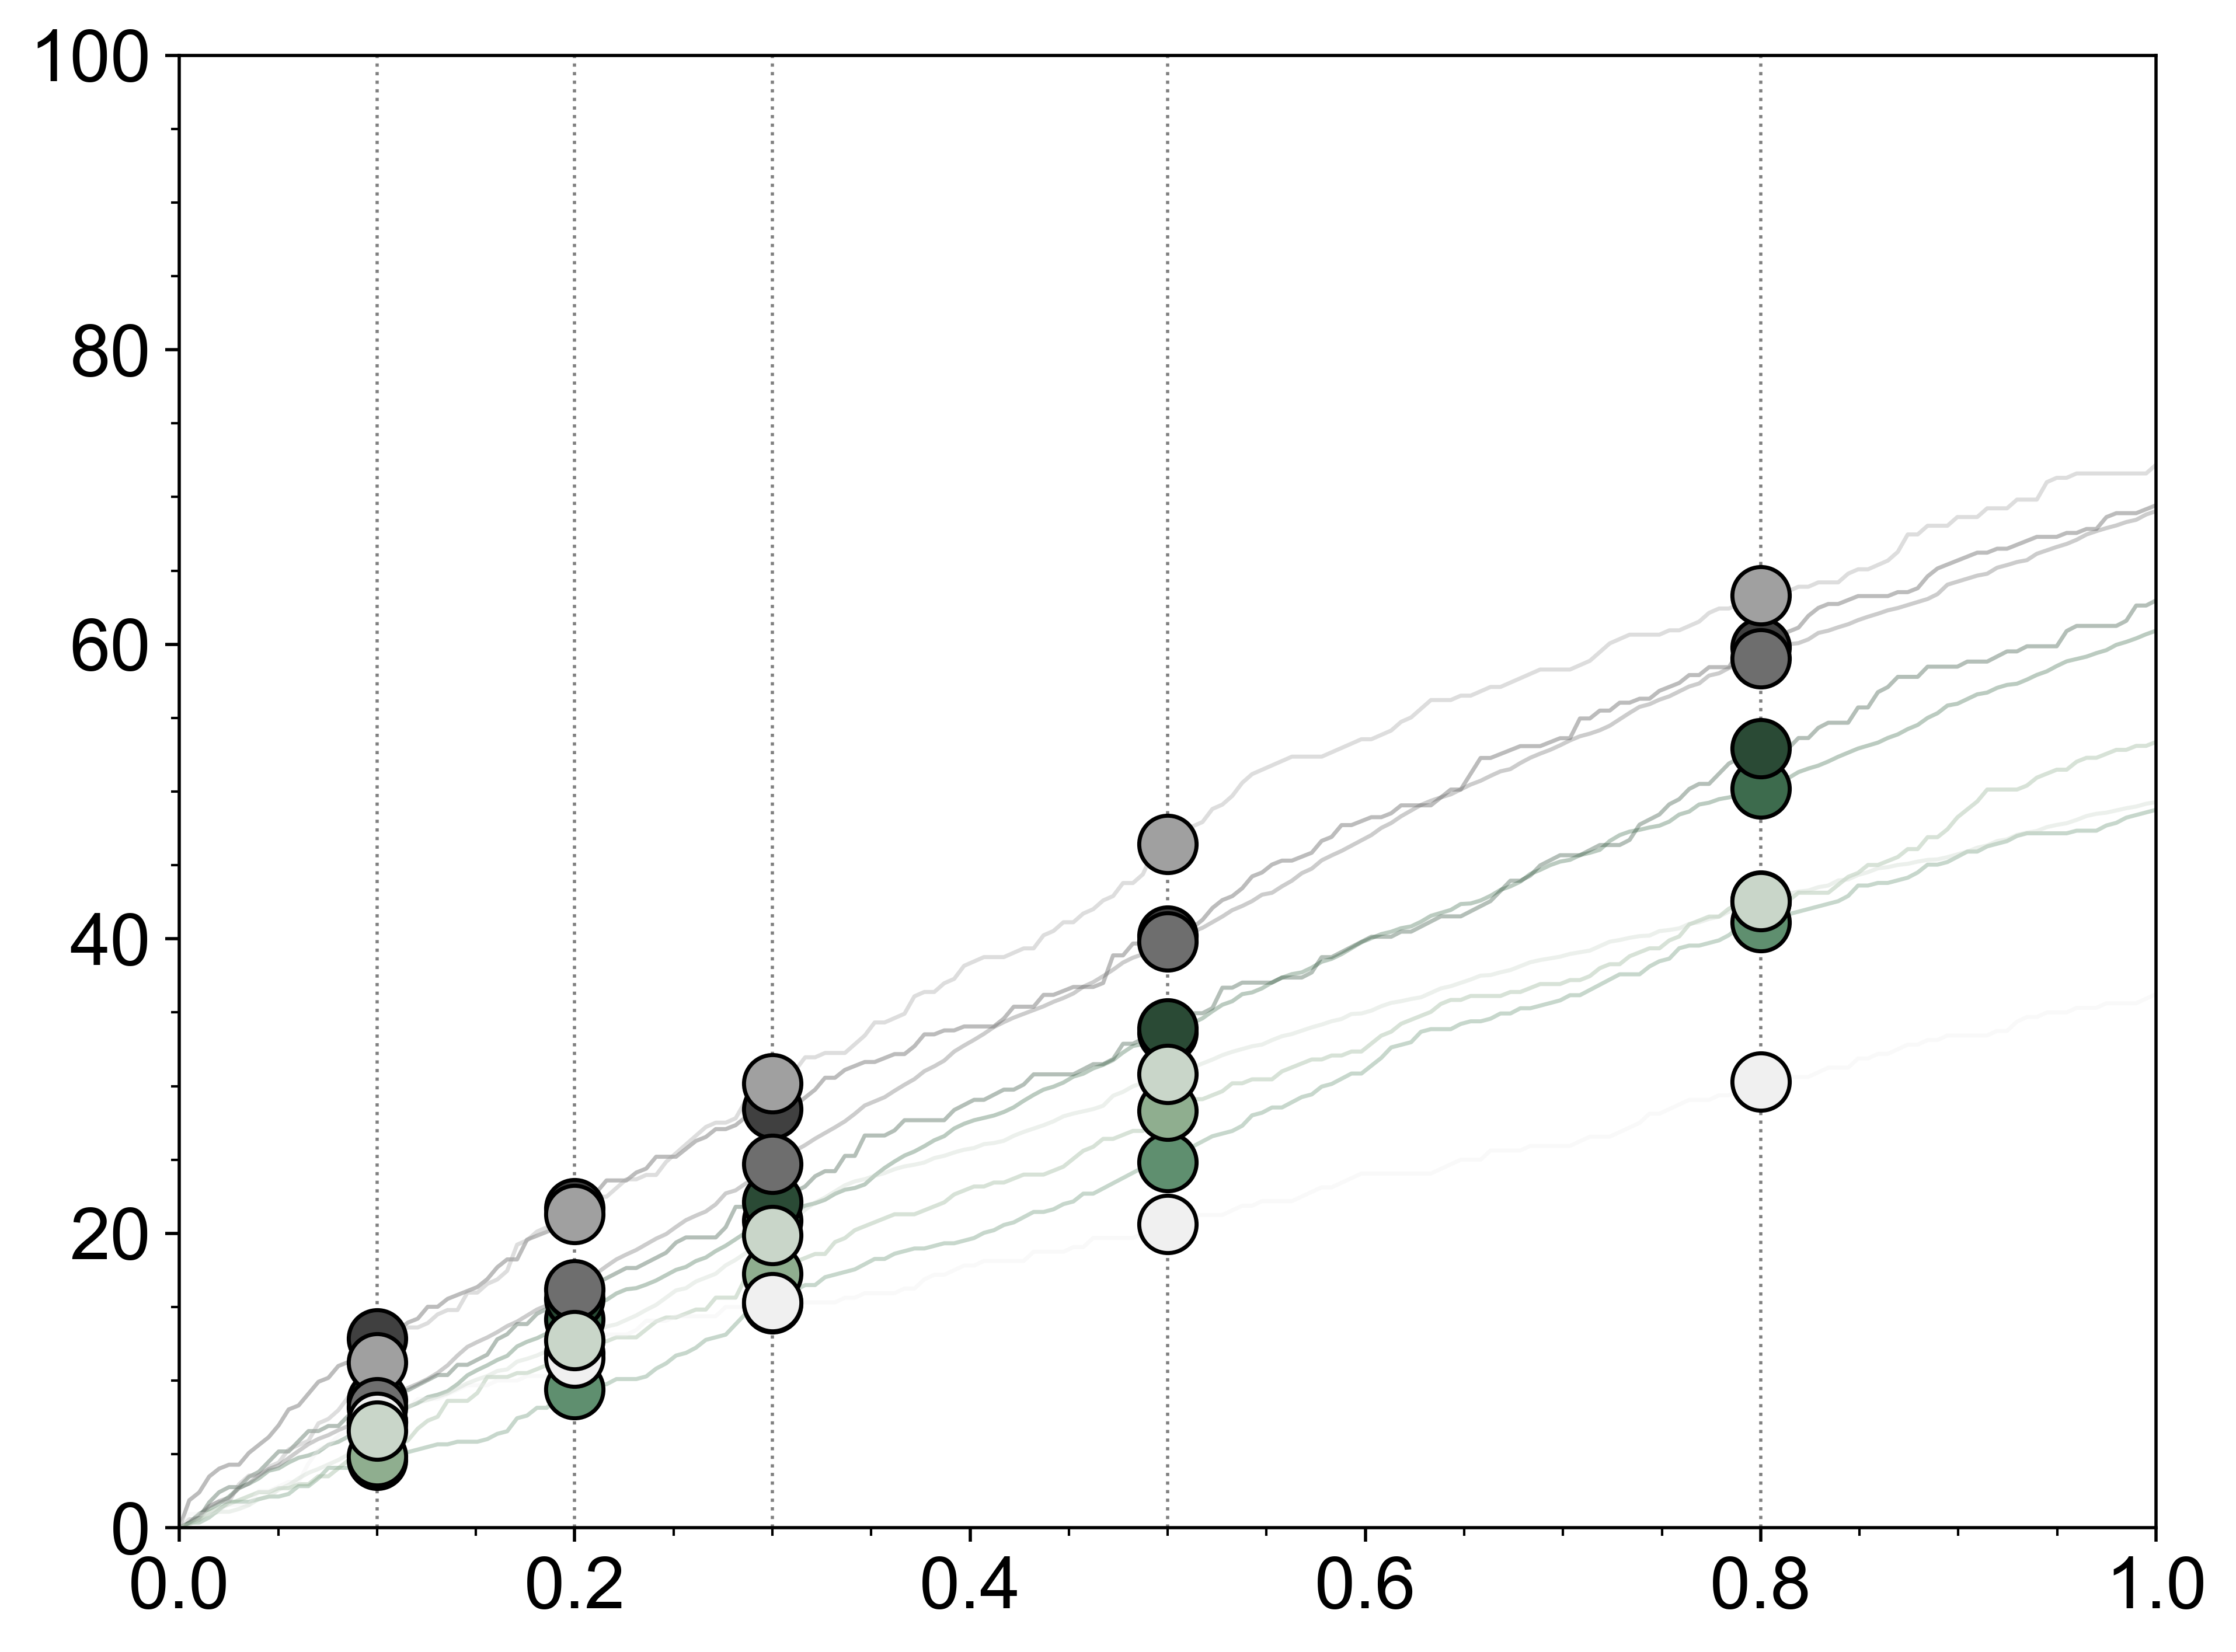

In [8]:
"""
Plot cumulative accuracy (fig 1) and target-vs-computed calibration (fig 2)
for selected ads_<num> csv files, each as its own standalone figure.

Expected file layout: ./data/ads_<num>/energies.csv
Expected columns:     ads_<num>_adsorption_E (GACE), ads_<num>_target_E (dataset)

Setup:
  - DATA_DIR: root folder containing per-adsorbate subfolders.
  - num_to_name: reverse-lookup of ads_dict (id -> adsorbate name) for legend labels.
  - FILTER_RANGE = (-10, 10): energy bounds (eV) used to discard outlier rows
    (expected to have been applied wherever `abs_errors` was built).
  - ERROR_THRESHOLDS: |GACE - target| cutoffs (eV) at which cumulative
    accuracy is reported/marked.
  - XLIM = (0, 1.0): x-axis range (eV) for the cumulative accuracy curve.
  - PALETTE / PALETTE_VIRIZION: discrete color ramp used to color each
    adsorbate's curve by how well GACE performs on it (worst -> best).

`color_for_rank(pos)`:
  Maps a normalized rank pos in [0, 1] (0 = worst, 1 = best) to a discrete
  color from PALETTE by nearest index.

Ranking:
  Uses a pre-existing `abs_errors` dict (adsorbate id -> absolute error
  series) to compute each adsorbate's mean absolute error, ranks
  adsorbates worst-to-best (highest to lowest mean error), and assigns
  each a normalized rank_pos used to pick its curve/marker color.

Figure 1 — cumulative accuracy:
  For each adsorbate: plots the percent of structures with absolute error
  <= t for a fine grid of thresholds (faint line), overlays discrete
  markers at ERROR_THRESHOLDS, and prints that adsorbate's accuracy at
  each threshold immediately within the same loop iteration. After the
  loop, prints the average accuracy at each threshold across adsorbates
  (equal weight per adsorbate, not per structure, since each adsorbate
  contributes one entry to pct_at_thresholds_all regardless of its
  structure count). Draws vertical dotted guide lines at each
  ERROR_THRESHOLDS value, sets axis limits, and saves the figure as
  "fig3/panel/cumulative_accuracy.svg" via `save_flat_svg`.
"""

num_to_name = {v: k for k, v in ads_dict.items()}  # for legend labels

# Discard any row where either column falls outside this range.
FILTER_RANGE = (-10, 10)

ERROR_THRESHOLDS = [0.10, 0.20, 0.30, 0.50, 0.80]
XLIM = (0, 1.0)

# Charizard-inspired palette: warm red/orange for worst, cooling to dark for best
PALETTE_VIRIZION = ["#f0f0f0", "#c9d6c9", "#8fae8f", "#5f8f6f", "#3d6b4d", "#2a4a35", "#a0a0a0", "#6e6e6e", "#404040"]
PALETTE = PALETTE_VIRIZION


def color_for_rank(pos):
    """pos in [0, 1] (0=worst, 1=best) -> discrete color from PALETTE."""
    idx = int(round(pos * (len(PALETTE) - 1)))
    return PALETTE[idx]


# rank: 0 = worst (highest mean error) -> 1 = best (lowest mean error)
mean_errors = {num: abs_errors[num].mean() for num in SELECTED_NUMS}
order = sorted(SELECTED_NUMS, key=lambda n: -mean_errors[n])  # worst first
rank_pos = {num: i / (len(order) - 1) for i, num in enumerate(order)}

# -------------------------------------------------------------
# Figure 1: cumulative accuracy
# -------------------------------------------------------------
fig_e, ax = plt.subplots(figsize=(8, 6), dpi=500)

thresholds_fine = np.linspace(*XLIM, 200)

pct_at_thresholds_all = []  # collect per-dataset values at ERROR_THRESHOLDS to average

for num in SELECTED_NUMS:
    abs_error = abs_errors[num]
    color = color_for_rank(rank_pos[num])

    pct_within = [(abs_error <= t).mean() * 100 for t in thresholds_fine]
    ax.plot(thresholds_fine, pct_within, linewidth=1, alpha=0.35, color=color)

    # discrete markers at the four thresholds of interest
    pct_at_thresholds = [(abs_error <= t).mean() * 100 for t in ERROR_THRESHOLDS]
    pct_at_thresholds_all.append(pct_at_thresholds)
    ax.scatter(ERROR_THRESHOLDS, pct_at_thresholds, s=200, color=color,
               edgecolor="black", linewidth=1, zorder=3, label=num_to_name.get(num, str(num)))
    
    key = next(k for k, v in ads_dict.items() if v == num)
    print(f"== {key} ==")
    for t, p in zip(ERROR_THRESHOLDS, pct_at_thresholds):
        print(f"  {t:.2f} eV: {p:.2f}%")
    print()


avg_pct_at_thresholds = np.mean(pct_at_thresholds_all, axis=0)  # equal weight per adsorbate
print("== average across adsorbates ==")
for t, pct in zip(ERROR_THRESHOLDS, avg_pct_at_thresholds):
    print(f"  {t:.2f} eV: {pct:.2f}%")

for t in ERROR_THRESHOLDS:
    ax.axvline(t, color="gray", linestyle=":", linewidth=0.8)

ax.minorticks_on()
ax.set_xlim(*XLIM)
ax.set_ylim(0, 100)
plt.tight_layout()
save_flat_svg(fig=fig_e, path=f"fig3/panel/cumulative_accuracy.svg")